# MiniBatch K-means 기반 Process 패턴 군집화와 이상탐지

연구 주제: **대규모 로그 데이터 기반 비지도 학습 이상탐지 AI 모델 개발**

세 기간의 **Process 원본 전체**를 입력으로 사용한다. Transaction은 부모 상태·단계 수 정합성 규칙의 문맥으로만 사용하며, 군집화 피처에는 넣지 않는다.

이 노트북은 **GLOBAL MiniBatch K-means 단독 비교 실험**이다. Adapter별 K-means 모델이나 GLOBAL+Adapter 앙상블을 구현한 것은 아니다. Adapter는 학습 표본 균형과 결과 해석에 사용한다. 기존 IF 모델·노트북·원본은 변경하지 않는다.

## 읽는 순서

1. 원본 분포와 하드 룰 전후 건수.
2. 학습·검증·이후 test의 범위와 학습 STATUS.
3. K 후보 비교 및 군집별 실제 패턴·Adapter 구성.
4. 군집별 거리 P99 판정선, 이상 후보 위치·발생 시점.
5. 같은 test 집단의 GLOBAL IF 단독 비교와 사례별 거리 근거.

작은 군집, 새로운 Process ID, STATUS 차이를 그 자체로 이상 라벨로 취급하지 않는다. 출력은 검토 후보이며 확정 장애나 정확도를 뜻하지 않는다. 그래프·표·해석은 노트북 출력에 포함하며 별도 결과 CSV/모델 저장 셀은 없다.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "code" / "analysis" / "log_analysis_common.py").is_file()
    and (p / "data").is_dir()
)
for folder in (ROOT / "code", ROOT / "code" / "analysis"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

from log_analysis_common import PERIODS, setup_plotting
from process_anomaly_pipeline.config import PipelineConfig
from process_anomaly_pipeline.data import load_workspace, chronological_split
from process_anomaly_pipeline.quantiles import QuantileBook
from process_anomaly_pipeline.rules import (
    RULE_NAMES, RULE_DESCRIPTIONS, CONSISTENCY_RULES,
    evaluate_rules, any_hits, model_eligible,
)
from process_anomaly_pipeline.pipeline import ProcessAnomalyPipeline
from minibatch_kmeans_common import (
    KMeansConfig, cluster_name, fit_experiment, score_experiment,
    distance_contributions, cluster_profiles, comparison_if_global,
    plot_counts, plot_input_distributions, plot_k_diagnostics,
    plot_projection, plot_score_margins, plot_cluster_distances,
    finish, count_axis, BLUE, RED, GRAY, FEATURE_LABELS,
)
setup_plotting()
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.titlesize": 13})
pd.set_option("display.max_columns", 22)
pd.set_option("display.max_rows", 30)

def table(frame, formats=None):
    formatters = {name: fmt.format for name, fmt in (formats or {}).items() if name in frame.columns}
    display(HTML(frame.to_html(formatters=formatters, na_rep="n.a.", border=0)))

def explain(observation, meaning, implication):
    display(Markdown(
        "**실제 결과**: " + observation
        + "\n\n**의미**: " + meaning
        + "\n\n**모델 개발에 반영**: " + implication
    ))


## 1. 실험 설정

**K=6은 시작 설정이지 검증된 최적값이 아니다.** K=2·4·6·8·12의 학습 거리와 독립 calibration 표본의 silhouette을 함께 확인한다. test를 보고 K를 자동으로 고르지 않는다.

기존 IF와 알고리즘 차이를 비교하기 위해 기본 학습 STATUS는 S이고, P99 수치 꼬리 제거·피처·시간 분할 정책도 동일하게 유지한다. S가 실제 정상이라는 보장은 없다. H/Z 추가 실험은 `TRAIN_STATUSES = ("S", "H", "Z")`로 바꿀 수 있지만, 학습 정책까지 달라지면 기존 IF와의 통제된 비교는 생략한다. N/P는 완료 처리시간 피처가 부족하므로 정상으로 합치지 않고 **모델 미평가**로 남긴다.


In [2]:
TRAIN_STATUSES = ("S",)
RULE_CONFIG = PipelineConfig()
KM_CONFIG = KMeansConfig(
    selected_k=6,
    candidates=(2, 4, 6, 8, 12),
    max_train_rows=100_000,
    batch_size=2_048,
    max_iter=100,
    n_init=5,
    random_state=42,
    quantile=0.99,
    min_cluster_threshold_rows=1_000,
    silhouette_rows=2_000,
    plot_rows=20_000,
)
if not TRAIN_STATUSES or not set(TRAIN_STATUSES).issubset({"S", "H", "Z"}):
    raise ValueError("학습 STATUS는 S/H/Z 중에서 명시적으로 선택해야 합니다.")

settings = pd.DataFrame([
    ("입력 단위", "Process 실행 1행", "Transaction은 정합성 규칙 문맥만 제공"),
    ("모델 구조", "GLOBAL MiniBatch K-means", "Adapter별 모델/앙상블과 구분"),
    ("학습 STATUS", ", ".join(TRAIN_STATUSES), "정상 후보 선택 정책; 확정 정상 라벨 아님"),
    ("학습 피처", "처리시간·건수·재시도 + 결측 표시 + 시간/요일 sin·cos", "10개, STATUS와 ID는 제외"),
    ("전처리", "log1p + 학습 중앙값 대체 + RobustScaler", "학습 표본에서만 fit, 거리 계산의 단위 영향 제어"),
    ("선택 K / 후보", f"{KM_CONFIG.selected_k} / {KM_CONFIG.candidates}", "K는 Adapter 개수와 다름"),
    ("학습 상한", f"{KM_CONFIG.max_train_rows:,}", "Adapter 균형 무복원 표본, 전수 통계와 구분"),
    ("batch_size / max_iter / n_init", f"{KM_CONFIG.batch_size:,} / {KM_CONFIG.max_iter} / {KM_CONFIG.n_init}", "초기 설정, 최적화 결과 아님"),
    ("random_state", str(KM_CONFIG.random_state), "재현 가능한 학습·그림 표본"),
    ("판정 분위수", f"P{KM_CONFIG.quantile * 100:g}", "독립 threshold 집단에서 고정, 이후 test 재산정 금지"),
    ("군집 판정선 최소 표본", f"{KM_CONFIG.min_cluster_threshold_rows:,}", "1% 꼬리에 기대 약 10행; 안정성 보장 아님"),
    ("작은 군집 fallback", "전체 threshold 집단 거리 P99", "낮은 지원 수를 숨기지 않고 기준 출처 표시"),
], columns=["설정", "값", "이유·한계"])
display(settings)


,설정,값,이유·한계
0,입력 단위,Process 실행 1행,Transaction은 정합성 규칙 문맥만 제공
1,모델 구조,GLOBAL MiniBatch K-means,Adapter별 모델/앙상블과 구분
2,학습 STATUS,S,정상 후보 선택 정책; 확정 정상 라벨 아님
3,학습 피처,처리시간·건수·재시도 + 결측 표시 + 시간/요일 sin·cos,"10개, STATUS와 ID는 제외"
4,전처리,log1p + 학습 중앙값 대체 + RobustScaler,"학습 표본에서만 fit, 거리 계산의 단위 영향 제어"
5,선택 K / 후보,"6 / (2, 4, 6, 8, 12)",K는 Adapter 개수와 다름
6,학습 상한,"100,000","Adapter 균형 무복원 표본, 전수 통계와 구분"
7,batch_size / max_iter / n_init,"2,048 / 100 / 5","초기 설정, 최적화 결과 아님"
8,random_state,42,재현 가능한 학습·그림 표본
9,판정 분위수,P99,"독립 threshold 집단에서 고정, 이후 test 재산정 금지"


## 2. 세 기간 원본과 STATUS 분포

기간은 2025-12-24~2026-04-06, 2026-08-15~2026-09-14, 2026-09-30~2026-10-02이다. 최근 기간은 파일명이 바뀌어 있어 **내용의 컬럼 구조**로 소스를 선택한다.

STATUS 의미: S 성공, F 실패, H 부분성공, Z 데이터없음, N 미처리, P 처리중. 원본의 중복·결측·파싱 오류는 조용히 삭제하지 않고 규칙에서 점검한다. 시간은 한국 시간 기준이다.


Process 원본: 3,714,199행 / Transaction 원본: 2,008,703행


,kind,period,source,rows,format
0,process,25년12월24일-26년4월6일,C:\Users\drago\OneDrive\바탕 화면\종설2\data\25년12월2...,3473285,csv
1,process,26년8월15일-26년9월14일,C:\Users\drago\OneDrive\바탕 화면\종설2\data\26년8월15...,213509,csv
2,process,26년9월30일-26년10월2일,C:\Users\drago\OneDrive\바탕 화면\종설2\data\26년9월30...,27405,csv
3,transaction,25년12월24일-26년4월6일,C:\Users\drago\OneDrive\바탕 화면\종설2\data\25년12월2...,1768054,csv
4,transaction,26년8월15일-26년9월14일,C:\Users\drago\OneDrive\바탕 화면\종설2\data\26년8월15...,213381,csv
5,transaction,26년9월30일-26년10월2일,C:\Users\drago\OneDrive\바탕 화면\종설2\data\26년9월30...,27268,sql


,Process 행 수,비중 (%)
status,,
S,"3,013,199",81.1265
F,"132,785",3.5751
H,37,0.0010
Z,619,0.0167
N,"565,464",15.2244
P,"2,095",0.0564


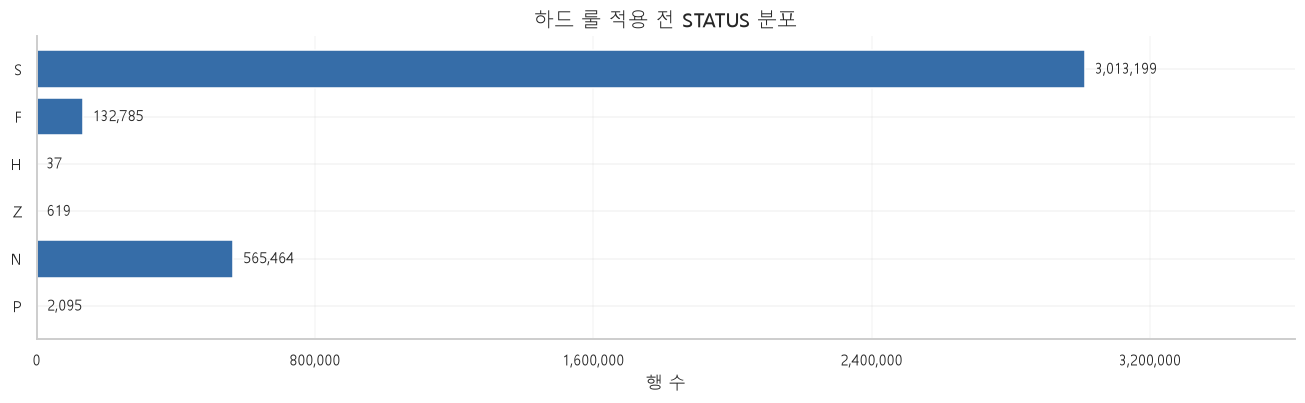

**실제 결과**: 전체 3,714,199행 중 N/P는 567,559행이다.

**의미**: 원본 STATUS 비중과 학습 STATUS 선택은 다른 개념이다. 작은 H/Z는 막대가 작아도 표에 정확한 건수를 표시했다.

**모델 개발에 반영**: 상태별 의미와 완료 여부를 구분하고, 학습에서 제외됐다는 이유만으로 정상 또는 이상으로 단정하지 않는다.

In [3]:
processes, transactions, source_audit = load_workspace(ROOT / "data", with_transactions=True)
print(f"Process 원본: {len(processes):,}행 / Transaction 원본: {len(transactions):,}행")
display(source_audit)
status_order = ["S", "F", "H", "Z", "N", "P"]
status_counts = processes.status.astype("string").fillna("결측").value_counts().reindex(status_order, fill_value=0)
status_summary = pd.DataFrame({"Process 행 수": status_counts, "비중 (%)": status_counts / len(processes) * 100})
table(status_summary, {"Process 행 수": "{:,.0f}", "비중 (%)": "{:.4f}"})
plot_counts(status_counts, "하드 룰 적용 전 STATUS 분포")
explain(
    f"전체 {len(processes):,}행 중 N/P는 {int(status_counts.reindex(['N', 'P']).sum()):,}행이다.",
    "원본 STATUS 비중과 학습 STATUS 선택은 다른 개념이다. 작은 H/Z는 막대가 작아도 표에 정확한 건수를 표시했다.",
    "상태별 의미와 완료 여부를 구분하고, 학습에서 제외됐다는 이유만으로 정상 또는 이상으로 단정하지 않는다.",
)


### 원본 수치 분포

아래는 모델 적용 전 **관측 가능한 원본 값**이다. 처리시간은 시작·종료가 있어 계산 가능한 비음수 값, 처리건수는 결측이 아닌 원본 값을 사용한다. N/P의 계산 불가능한 처리시간은 0으로 채우지 않는다.

처리시간 히스토그램은 일반 막대와 선형 축으로 그린다. 중앙 99% 부근으로 확대할 때 화면 밖 행 수를 표시하며, 모델과 원본 통계에서는 해당 행을 유지한다. 처리건수는 0·1·2~9·10~99 등 의미 있는 구간별 전수 막대로 집계한다. 구간 폭은 서로 다르며 막대 높이는 행 수이다.


원본 처리시간 계산 가능·비음수: 3,146,616행
원본 처리시간 결측: 567,583행


,count,mean,std,min,50%,95%,99%,99.9%,max
duration_ms,"3,146,616.000","2,906.564","6,527.784",0.000,619.000,"8,699.000","9,655.000","19,579.385","1,802,839.000"
totalCount,"3,714,194.000","210,852.024","3,699,527.350",0.000,"10,000.000","10,000.000","10,485,760.000","10,485,760.000","524,288,000.000"
retryCount,"3,714,199.000",0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


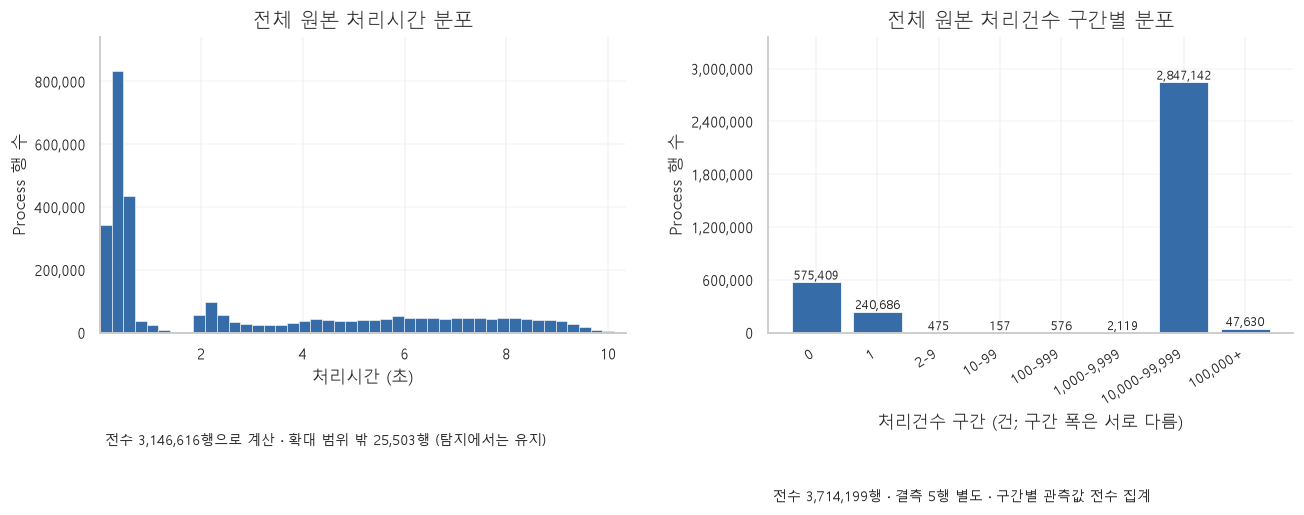

**실제 결과**: 수치 요약은 원본 전수의 결측 제외 관측값으로 계산했다. 그림의 처리시간 단위는 초, 요약 표는 ms이다.

**의미**: 히스토그램의 빈 구간·큰 피크·긴 꼬리는 원본 데이터의 특징이며, 군집을 만든 결과가 아니다.

**모델 개발에 반영**: 거리 기반 모델에는 큰 값의 단위 영향이 있어 log1p와 RobustScaler를 사용하되 원본 단위의 표도 함께 본다.

In [4]:
raw_numeric = processes.loc[processes.duration_ms.ge(0)]
print(f"원본 처리시간 계산 가능·비음수: {len(raw_numeric):,}행")
print(f"원본 처리시간 결측: {int(processes.duration_ms.isna().sum()):,}행")
table(
    processes[["duration_ms", "totalCount", "retryCount"]].describe(percentiles=[.5, .95, .99, .999]).T,
    {c: "{:,.3f}" for c in ["count", "mean", "std", "min", "50%", "95%", "99%", "99.9%", "max"]},
)
plot_input_distributions(processes, cohort_label="전체 원본")
explain(
    "수치 요약은 원본 전수의 결측 제외 관측값으로 계산했다. 그림의 처리시간 단위는 초, 요약 표는 ms이다.",
    "히스토그램의 빈 구간·큰 피크·긴 꼬리는 원본 데이터의 특징이며, 군집을 만든 결과가 아니다.",
    "거리 기반 모델에는 큰 값의 단위 영향이 있어 log1p와 RobustScaler를 사용하되 원본 단위의 표도 함께 본다.",
)


## 3. 하드 룰과 시간 분할

기존 파이프라인의 규칙 평가를 재사용한다. STATUS F, 정합성 위반, SQL 필수값 결측, 역전 시각, 음수·소수 건수, 학습 구간에서 고정한 P99/P99.9 초과 등을 먼저 분리한다.

Transaction 관계 규칙은 **세 기간의 전체 파일을 완전 문맥으로 선언**한 조건에서 평가한다. 파일이 실제로 모든 단계를 포함한다는 별도 증명은 아니며, 부모 연결 불가·모호함은 판정 불가로 남긴다.

동일 기간+transactionId에 속한 Process·재시도는 같은 시간 분할에 둔다. 과거 60% 관측 날짜는 train, 다음 20%는 validation, 이후 20%는 test이다. validation은 거래 해시로 calibration과 threshold 집단에 분리한다. **test는 이미 수집된 로그 중 학습·기준선 산정에 사용하지 않은 이후 기간**이지 미래를 예측한 결과가 아니다.


,규칙,설명,독립 탐지 행,판정 불가 행
0,status_failed,STATUS=F: 로그에 실패가 명시됨,132785,0
1,tx_success_all_process_failed,Tx S이고 기대 단계가 모두 관측됐으며 전부 F,1,703612
2,process_count_mismatch,완료 거래의 processCount와 관측 고유 Process ID 수가 다름,5479,12180
3,success_with_error,Process S인데 errorCount>0,10,701000
4,count_conservation,완료 Process에서 totalCount != successCount+errorC...,26,567559
5,final_missing_end,S/F/H/Z인데 endTime 없음,25,567559
6,missing_sql_required,Process PK/NOT NULL 컬럼 결측,0,0
7,negative_duration,종료시각이 시작시각보다 허용 오차 이상 앞섬,0,567583
8,invalid_count_domain,건수/재시도가 음수 또는 비정수,0,0
9,statistical_tail,학습 구간에서 고정한 P99/P99.9 초과,29393,0


부모 연결 불가·모호함: 6,146행
원본 3,714,199 = 규칙 후보 167,310 + 규칙 미탐지 3,546,889
규칙 미탐지 3,546,889 = 모델 평가 가능 2,985,466 + 미평가 561,423


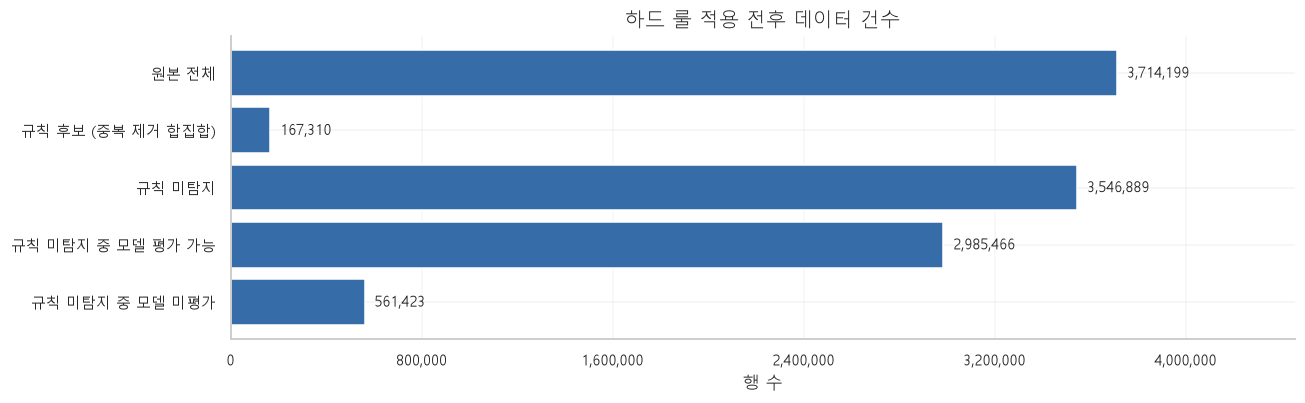

**실제 결과**: 규칙 후보는 167,310행이며, 그 이후 모델 대상은 2,985,466행이다.

**의미**: 규칙별 탐지 행 수는 중복될 수 있다. 합집합으로 센 후보 수만 전후 건수에 사용했다. 판정 불가는 미탐지/정상 확인과 다르다.

**모델 개발에 반영**: 모델 미평가를 정상에 포함하지 않는다. 규칙 후보와 모델만 추가로 찾은 후보를 분리한다.

In [5]:
flags, transaction_context = evaluate_rules(
    processes, RULE_CONFIG, transactions=transactions, complete_context=True,
)
split = chronological_split(processes, RULE_CONFIG)
eligible = model_eligible(processes, flags)
base_reference = (
    eligible & processes.status.isin(TRAIN_STATUSES)
    & ~any_hits(flags, CONSISTENCY_RULES)
)
train_before_tail = processes.loc[split.eq("train") & base_reference]
quantile_book = QuantileBook.fit(train_before_tail, RULE_CONFIG)
flags["statistical_tail"], _quantile_details = quantile_book.evaluate(processes)
del _quantile_details

reference = base_reference.copy()
if RULE_CONFIG.exclude_statistical_from_training:
    reference &= ~flags.statistical_tail.fillna(False)
rule_hit = any_hits(flags, RULE_NAMES)
usable_split = split.isin(["train", "calibration", "threshold", "test"])
scoreable = ~rule_hit & eligible & usable_split

rule_audit = pd.DataFrame([
    {"규칙": name, "설명": RULE_DESCRIPTIONS[name],
     "독립 탐지 행": int(flags[name].fillna(False).sum()),
     "판정 불가 행": int(flags[name].isna().sum())}
    for name in RULE_NAMES
])
display(rule_audit)
print(f"부모 연결 불가·모호함: {int(transaction_context.context_state.eq('missing_or_ambiguous_parent').sum()):,}행")
print(f"원본 {len(processes):,} = 규칙 후보 {int(rule_hit.sum()):,} + 규칙 미탐지 {int((~rule_hit).sum()):,}")
print(f"규칙 미탐지 {int((~rule_hit).sum()):,} = 모델 평가 가능 {int(scoreable.sum()):,} + 미평가 {int((~rule_hit & ~scoreable).sum()):,}")
rule_flow = pd.Series({
    "원본 전체": len(processes),
    "규칙 후보 (중복 제거 합집합)": int(rule_hit.sum()),
    "규칙 미탐지": int((~rule_hit).sum()),
    "규칙 미탐지 중 모델 평가 가능": int(scoreable.sum()),
    "규칙 미탐지 중 모델 미평가": int((~rule_hit & ~scoreable).sum()),
})
plot_counts(rule_flow, "하드 룰 적용 전후 데이터 건수")
explain(
    f"규칙 후보는 {int(rule_hit.sum()):,}행이며, 그 이후 모델 대상은 {int(scoreable.sum()):,}행이다.",
    "규칙별 탐지 행 수는 중복될 수 있다. 합집합으로 센 후보 수만 전후 건수에 사용했다. 판정 불가는 미탐지/정상 확인과 다르다.",
    "모델 미평가를 정상에 포함하지 않는다. 규칙 후보와 모델만 추가로 찾은 후보를 분리한다.",
)


### 학습에 실제로 사용되는 STATUS와 기간


In [6]:
selection_by_status = pd.DataFrame([
    {"STATUS": s,
     "원본 행": int(processes.status.eq(s).sum()),
     "규칙 후보": int((processes.status.eq(s) & rule_hit).sum()),
     "모델 평가 가능": int((processes.status.eq(s) & scoreable).sum()),
     "train 정상 후보": int((processes.status.eq(s) & reference & split.eq("train")).sum())}
    for s in status_order
])
display(selection_by_status)
split_audit = pd.DataFrame([
    {"분할": name, "원본 행": int(split.eq(name).sum()),
     "규칙 후보": int((split.eq(name) & rule_hit).sum()),
     "규칙 미탐지 모델 미평가": int((split.eq(name) & ~rule_hit & ~scoreable).sum()),
     "정상 후보 행": int((split.eq(name) & reference).sum()),
     "모델 평가 대상": int((split.eq(name) & scoreable).sum()),
     "첫 시작": processes.loc[split.eq(name), "startTime"].min(),
     "마지막 시작": processes.loc[split.eq(name), "startTime"].max()}
    for name in ["train", "calibration", "threshold", "test",
                 "excluded_missing_time_or_id", "excluded_boundary_transaction"]
])
display(split_audit)
train = processes.loc[split.eq("train") & reference]
calibration = processes.loc[split.eq("calibration") & reference]
threshold = processes.loc[split.eq("threshold") & reference]
test_frame = processes.loc[split.eq("test") & scoreable]
print(f"학습 후보 {len(train):,} / calibration {len(calibration):,} / threshold {len(threshold):,} / 실제 test 평가 {len(test_frame):,}")
display(quantile_book.table().query("group == 'GLOBAL'"))
explain(
    f"학습 STATUS 설정은 {TRAIN_STATUSES}, test 실제 평가 대상은 {len(test_frame):,}행이다.",
    "훈련에서 제외한 H/Z도 규칙 미탐지·완료·유효 입력이면 추론 대상이 될 수 있다. 학습 정책과 추론 조건은 다르다.",
    "S-only와 S/H/Z 학습 비교는 알고리즘 비교와 별도 실험으로 수행한다.",
)


,STATUS,원본 행,규칙 후보,모델 평가 가능,train 정상 후보
0,S,3013199,28366,2984832,2582379
1,F,132785,132785,0,0
2,H,37,9,28,0
3,Z,619,13,606,0
4,N,565464,5332,0,0
5,P,2095,805,0,0


,분할,원본 행,규칙 후보,규칙 미탐지 모델 미평가,정상 후보 행,모델 평가 대상,첫 시작,마지막 시작
0,train,3175652,32831,560405,2582379,2582416,2025-12-24 10:25:31.689,2026-03-20 17:04:27.315
1,calibration,213556,29445,310,183514,183801,2026-03-23 08:15:23.871,2026-08-19 23:59:55.042
2,threshold,213113,29350,309,183239,183454,2026-03-23 08:12:59.703,2026-08-19 23:59:50.045
3,test,111549,75674,80,35700,35795,2026-08-20 00:00:00.295,2026-10-02 15:36:59.559
4,excluded_missing_time_or_id,325,7,318,0,0,NaT,NaT
5,excluded_boundary_transaction,4,3,1,1,0,2026-01-12 10:28:56.989,2026-04-02 11:14:00.511


학습 후보 2,582,379 / calibration 183,514 / threshold 183,239 / 실제 test 평가 35,795


,group,metric,quantile,threshold,reference_rows
0,GLOBAL,duration_ms,0.990,9.728000e+03,2608452
1,GLOBAL,duration_ms,0.999,1.838555e+04,2608452
2,GLOBAL,totalCount,0.990,1.048576e+07,2608452
3,GLOBAL,totalCount,0.999,1.048576e+07,2608452
4,GLOBAL,retryCount,0.990,0.000000e+00,2608452
5,GLOBAL,retryCount,0.999,0.000000e+00,2608452


**실제 결과**: 학습 STATUS 설정은 ('S',), test 실제 평가 대상은 35,795행이다.

**의미**: 훈련에서 제외한 H/Z도 규칙 미탐지·완료·유효 입력이면 추론 대상이 될 수 있다. 학습 정책과 추론 조건은 다르다.

**모델 개발에 반영**: S-only와 S/H/Z 학습 비교는 알고리즘 비교와 별도 실험으로 수행한다.

## 4. 군집 학습과 K 후보 비교

MiniBatch K-means는 학습된 피처 공간에서 중심까지의 제곱거리 합을 줄이는 군집화다. 군집 라벨만으로 이상 여부를 판정하지 않으므로 이 실험에서는 **중심 거리 + 독립 검증 P99**를 추가한다.

모든 K 후보에 동일 학습 표본·전처리를 사용한다. silhouette은 독립 calibration의 균등 표본으로 계산하므로 소수 패턴이 덜 나타날 수 있다. 이 값은 **군집 분리 지표이지 이상탐지 정확도가 아니다**.

참고: [MiniBatchKMeans 공식 문서](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html), [공식 비교 예제](https://scikit-learn.org/stable/auto_examples/cluster/plot_mini_batch_kmeans.html).


,K,train_mean_squared_distance,calibration_silhouette,silhouette_rows,silhouette_observed_clusters,smallest_train_sample_cluster,fit_and_diagnostic_seconds,selected
0,2,1.5534,0.3858,2000,2,35713,0.313,False
1,4,1.2016,0.3409,2000,4,19480,0.375,False
2,6,0.8932,0.1555,2000,6,11317,0.390,True
3,8,0.7647,0.2450,2000,7,6595,0.282,False
4,12,0.6161,0.2684,2000,7,2255,0.312,False


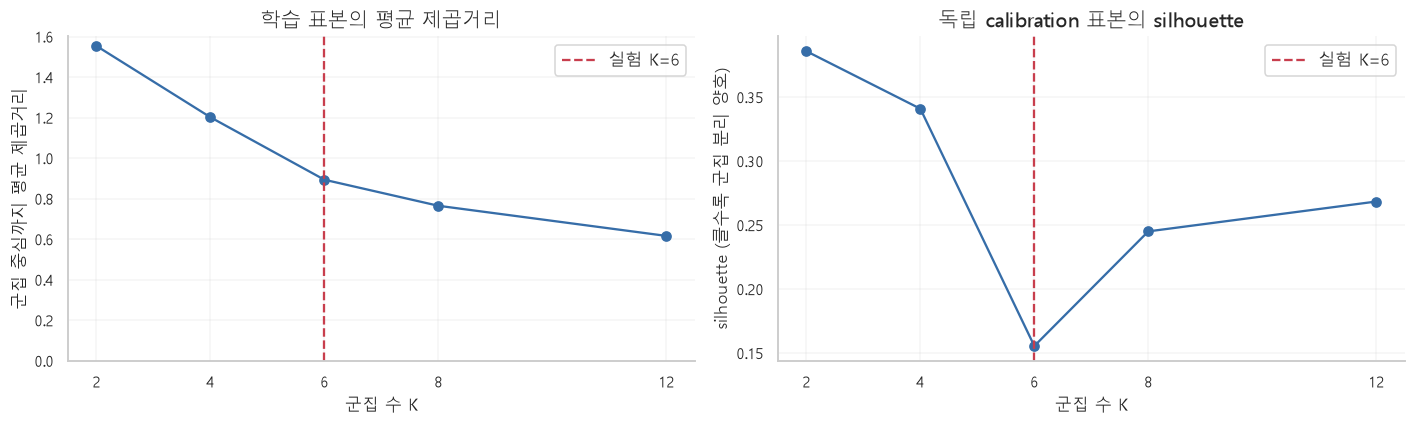

,학습 후보 전수,실제 학습 표본
adapterType,,
DB.READER,1266772,25521
DB.WRITER,1266649,25521
FILE.READER,24151,24151
FILE.WRITER,22136,22136
SERVICE.EXECUTOR,2621,2621
DATA.TRANSFORMER,11,11
CLIENT_STUB,10,10
DB.UPDATER,8,8
DATA.MAPPER,7,7


,피처,학습 표본 고유값 수
0,log_duration_ms,9586
1,missing_duration_ms,1
2,log_totalCount,15
3,missing_totalCount,1
4,log_retryCount,1
5,missing_retryCount,1
6,hour_sin,14
7,hour_cos,14
8,weekday_sin,7
9,weekday_cos,5


**실제 결과**: 학습 후보 2,582,379행 중 100,000행을 사용했고, 실험 K=6; calibration silhouette 최고 후보 K=2.

**의미**: K를 늘리면 학습 거리는 대체로 줄지만 작은 패턴을 지나치게 나눌 수 있다. 학습 상수 피처는 현재 군집 분리에 기여하지 않는다.

**모델 개발에 반영**: K=6을 최적 모델로 선언하지 않는다. 표본·기간·알림 사례의 안정성을 추가로 비교해야 한다.

In [7]:
bundle = fit_experiment(train, calibration, threshold, KM_CONFIG)
display(bundle["k_diagnostics"].round(4))
plot_k_diagnostics(bundle["k_diagnostics"], KM_CONFIG.selected_k)
sampling_audit = pd.concat(
    [train.adapterType.value_counts().rename("학습 후보 전수"),
     bundle["train_sample"].adapterType.value_counts().rename("실제 학습 표본")],
    axis=1,
).fillna(0).astype(int)
display(sampling_audit)
audit_features = bundle["encoder"].transform(bundle["train_sample"])
feature_audit = pd.DataFrame({
    "피처": bundle["encoder"].columns,
    "학습 표본 고유값 수": [
        len(np.unique(audit_features[:, i]))
        for i in range(len(bundle["encoder"].columns))
    ],
})
display(feature_audit)
diagnostics = bundle["k_diagnostics"].dropna(subset=["calibration_silhouette"])
best_k = int(diagnostics.loc[diagnostics.calibration_silhouette.idxmax(), "K"]) if len(diagnostics) else None
explain(
    f"학습 후보 {len(train):,}행 중 {len(bundle['train_sample']):,}행을 사용했고, 실험 K={KM_CONFIG.selected_k}; calibration silhouette 최고 후보 K={best_k}.",
    "K를 늘리면 학습 거리는 대체로 줄지만 작은 패턴을 지나치게 나눌 수 있다. 학습 상수 피처는 현재 군집 분리에 기여하지 않는다.",
    "K=6을 최적 모델로 선언하지 않는다. 표본·기간·알림 사례의 안정성을 추가로 비교해야 한다.",
)


## 5. 군집별 이상 판정 기준

각 평가 행에 대해 학습된 **가장 가까운 군집 중심**을 찾는다.

- 거리: 전처리된 전체 10개 피처 공간의 유클리드 거리.
- 군집 판정선: 독립 threshold 정상 후보 중 **해당 군집 거리의 P99**.
- threshold 표본이 1,000행 미만인 군집: 전체 threshold 거리 P99로 fallback.
- 모델 후보: **거리 > 해당 군집 판정선**. 같으면 후보가 아니다.
- 초과폭: **거리 − 판정선**. 양수면 후보이며, 아래 공통 점수 그림의 점선은 0이다.

P99는 검증 기준집단의 상위 약 1%를 검토하겠다는 설정이다. 실제 이상 비율이나 test에서 반드시 1% 탐지한다는 뜻은 아니다. fallback이 항상 정확하거나 보수적이라는 보장도 없다.


In [8]:
threshold_view = bundle["thresholds"].copy()
threshold_view["군집"] = threshold_view.cluster.map(cluster_name)
table(threshold_view.drop(columns="cluster").set_index("군집"), {
    "threshold_rows": "{:,.0f}", "distance_threshold": "{:.4f}",
    "expected_tail_rows": "{:.1f}", "reference_exceed_rows": "{:,.0f}",
    "reference_median_distance": "{:.4f}",
})
print(f"전체 거리 fallback 판정선: {bundle['pooled_threshold']:.6f}")
print(f"threshold 기준집단 합계: {int(threshold_view.threshold_rows.sum()):,}행")
assert int(threshold_view.threshold_rows.sum()) == len(threshold)


,threshold_rows,distance_threshold,threshold_basis,expected_tail_rows,reference_exceed_rows,reference_median_distance
군집,,,,,,
C1,"10,687",2.9074,cluster_P99,106.9,98,2.4480
C2,"53,670",2.8460,cluster_P99,536.7,532,1.3286
C3,"79,571",2.7203,cluster_P99,795.7,787,1.5897
C4,"5,073",2.5091,cluster_P99,50.7,45,2.4316
C5,"1,344",2.5540,cluster_P99,13.4,14,2.4016
C6,"32,894",1.8070,cluster_P99,328.9,327,1.3649


전체 거리 fallback 판정선: 2.854259
threshold 기준집단 합계: 183,239행


### 전수 추론과 최종 건수

군집 학습은 표본을 사용하지만 **모델 평가 대상 전체**에 점수를 계산한다. 하드 룰 후보는 앞 단계 결과를 유지하고 모델 점수로 덮어쓰지 않는다. N/P 등 미평가 행에는 거리·군집·판정선이 없다.


,Process 행 수
decision,
모델 판정선 이하,2981467
모델 미평가,561423
규칙 후보,167310
모델 추가 후보,3999


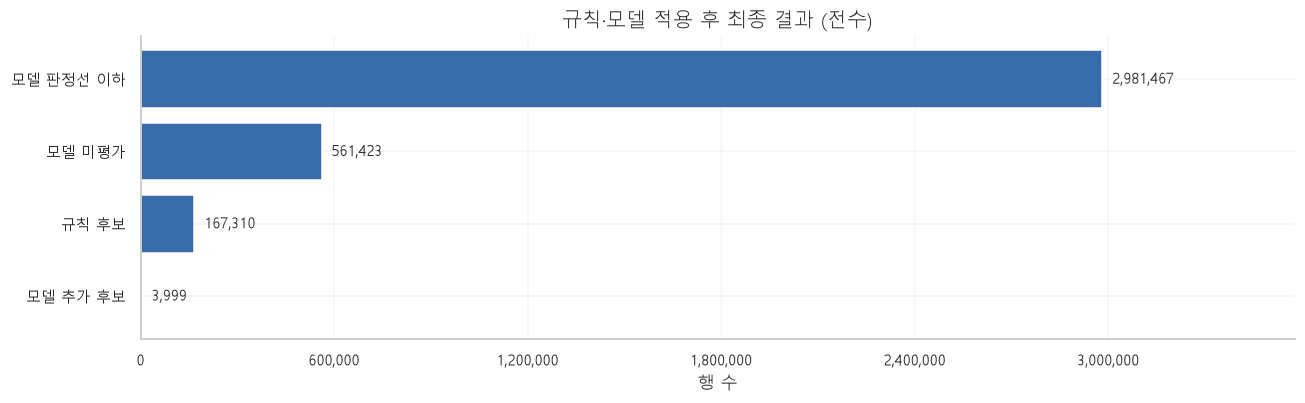

,분할,평가 행,모델 추가 후보
0,train,2582416,16
1,calibration,183801,2066
2,threshold,183454,1915
3,test,35795,2


**실제 결과**: 전수 모델 추가 후보 3,999행, 이후 test 추가 후보 2행 / 평가 35,795행 (0.01%).

**의미**: 학습 데이터의 후보율은 일반화 성능이 아니다. 이후 test 후보율이 검증 1%와 다른 것은 기간별 패턴 변화 등의 영향일 수 있다.

**모델 개발에 반영**: 핵심 모델 비교는 동일한 이후 test 행과 고정된 판정선에서 수행한다.

In [9]:
scored = score_experiment(bundle, processes.loc[scoreable])
result = pd.DataFrame(index=processes.index)
result["rule_candidate"] = rule_hit
result["model_assessed"] = scoreable
result["cluster"] = np.nan
for col in ["distance", "distance_threshold", "score_margin"]:
    result[col] = np.nan
result["threshold_basis"] = pd.Series(pd.NA, index=result.index, dtype="string")
result["model_candidate"] = False
for col in scored.columns:
    result.loc[scored.index, col] = scored[col]
result["final_candidate"] = result.rule_candidate | result.model_candidate
result["decision"] = "모델 미평가"
result.loc[result.model_assessed, "decision"] = "모델 판정선 이하"
result.loc[result.model_candidate, "decision"] = "모델 추가 후보"
result.loc[result.rule_candidate, "decision"] = "규칙 후보"
result["decision"] = result.decision.astype("category")

decision_counts = result.decision.value_counts()
display(decision_counts.to_frame("Process 행 수"))
assert int(decision_counts.sum()) == len(processes)
assert not bool((result.rule_candidate & result.model_candidate).any())
assert int(result.final_candidate.sum()) == int(result.rule_candidate.sum() + result.model_candidate.sum())
plot_counts(decision_counts, "규칙·모델 적용 후 최종 결과 (전수)")
test_result = scored.loc[test_frame.index]
display(pd.DataFrame([
    {"분할": name, "평가 행": int((split.loc[scored.index] == name).sum()),
     "모델 추가 후보": int(scored.loc[split.loc[scored.index].eq(name), "model_candidate"].sum())}
    for name in ["train", "calibration", "threshold", "test"]
]))
explain(
    f"전수 모델 추가 후보 {int(scored.model_candidate.sum()):,}행, 이후 test 추가 후보 {int(test_result.model_candidate.sum()):,}행 / 평가 {len(test_result):,}행 ({test_result.model_candidate.mean():.2%}).",
    "학습 데이터의 후보율은 일반화 성능이 아니다. 이후 test 후보율이 검증 1%와 다른 것은 기간별 패턴 변화 등의 영향일 수 있다.",
    "핵심 모델 비교는 동일한 이후 test 행과 고정된 판정선에서 수행한다.",
)


## 6. 군집에 어떤 Process들이 들어갔는가?

C1~C6은 군집 중심의 처리시간 순서로 붙인 **읽기용 이름**이다. 업무명·Adapter ID가 아니며 재학습하면 이름의 대응이 바뀔 수 있다.

아래 통계는 그림 표본이 아니라 모델 평가 대상 전수이다. 처리시간·건수의 실제 중앙값, 상위 Adapter 구성, 이후 test의 후보율을 함께 읽는다.


,rows,candidate_rows,candidate_pct,median_duration_seconds,p95_duration_seconds,median_totalCount,top_adapter,top_adapter_pct
군집,,,,,,,,
C1,"435,306",214,0.05,0.3370,0.6620,"10,000.00",DB.READER,91.31
C2,"347,236","1,376",0.40,0.4310,2.0360,"10,000.00",DB.READER,83.92
C3,"473,895","1,592",0.34,0.4420,2.2220,"10,000.00",DB.READER,81.00
C4,"353,861",100,0.03,0.4500,0.6480,"10,000.00",DB.READER,92.50
C5,"452,938",28,0.01,3.9960,8.7710,"10,000.00",DB.WRITER,90.45
C6,"922,230",689,0.07,6.6030,9.2170,"10,000.00",DB.WRITER,99.93


,rows,candidate_rows,candidate_pct,median_duration_seconds,p95_duration_seconds,median_totalCount,top_adapter,top_adapter_pct
군집,,,,,,,,
C1,"9,585",0,0.00,0.0240,0.1270,1.00,SERVICE.EXECUTOR,97.93
C2,32,0,0.00,0.1245,0.4919,3.00,SERVICE.EXECUTOR,46.88
C3,4,0,0.00,0.2550,0.7004,1.00,SERVICE.EXECUTOR,50.00
C4,0,0,n.a.,n.a.,n.a.,n.a.,관측 없음,n.a.
C5,"26,161",0,0.00,5.9560,5.9880,1.00,SERVICE.EXECUTOR,99.59
C6,13,2,15.38,6.8290,8.5492,"1,000.00",DB.WRITER,84.62


,최빈 시작 시간대,해당 시간대 비중 (%),최빈 시작 요일,해당 요일 비중 (%)
cluster,,,,
C1,17시,6.62,금,50.34
C2,17시,10.37,일,64.86
C3,02시,9.39,월,46.76
C4,07시,4.27,토,100.00
C5,17시,6.13,금,46.14
C6,12시,5.20,일,35.74


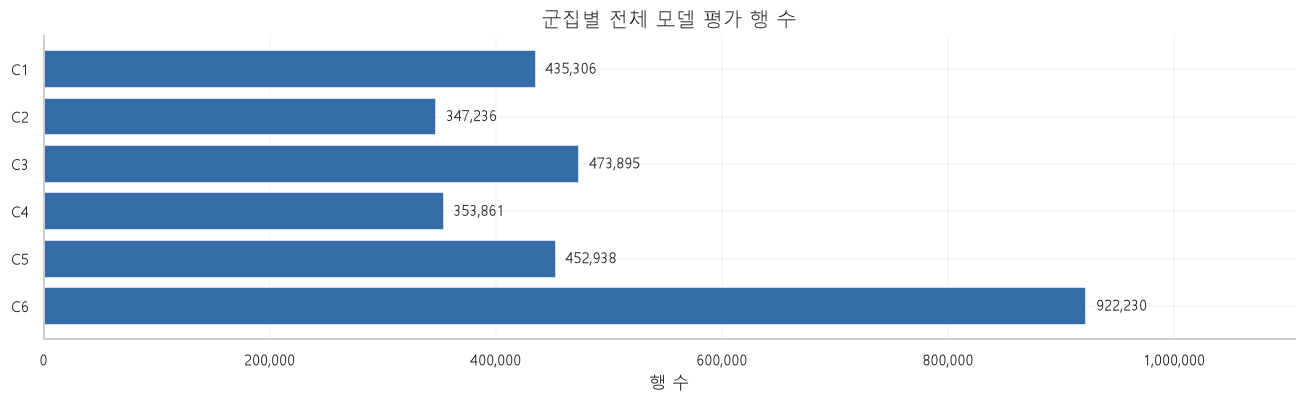

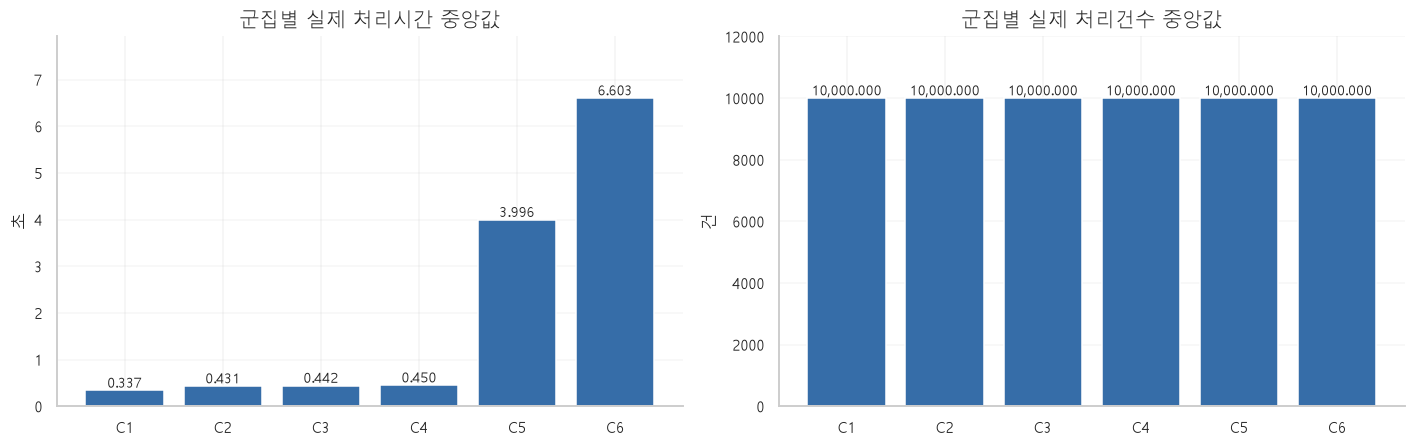

**실제 결과**: C1: 435,306행, 처리시간 중앙값 0.3370초, 처리건수 중앙값 10,000.00건, 최다 Adapter DB.READER (91.31%).

**의미**: 이 군집의 관측 패턴 요약이다. 같은 Adapter가 여러 군집에 속할 수 있고 여러 Adapter가 같은 군집에 섞일 수 있다.

**모델 개발에 반영**: 군집이 업무 집단을 잘 대변하는지 Adapter 구성·시간대·개별 사례와 함께 검토한다.

**실제 결과**: C2: 347,236행, 처리시간 중앙값 0.4310초, 처리건수 중앙값 10,000.00건, 최다 Adapter DB.READER (83.92%).

**의미**: 이 군집의 관측 패턴 요약이다. 같은 Adapter가 여러 군집에 속할 수 있고 여러 Adapter가 같은 군집에 섞일 수 있다.

**모델 개발에 반영**: 군집이 업무 집단을 잘 대변하는지 Adapter 구성·시간대·개별 사례와 함께 검토한다.

**실제 결과**: C3: 473,895행, 처리시간 중앙값 0.4420초, 처리건수 중앙값 10,000.00건, 최다 Adapter DB.READER (81.00%).

**의미**: 이 군집의 관측 패턴 요약이다. 같은 Adapter가 여러 군집에 속할 수 있고 여러 Adapter가 같은 군집에 섞일 수 있다.

**모델 개발에 반영**: 군집이 업무 집단을 잘 대변하는지 Adapter 구성·시간대·개별 사례와 함께 검토한다.

**실제 결과**: C4: 353,861행, 처리시간 중앙값 0.4500초, 처리건수 중앙값 10,000.00건, 최다 Adapter DB.READER (92.50%).

**의미**: 이 군집의 관측 패턴 요약이다. 같은 Adapter가 여러 군집에 속할 수 있고 여러 Adapter가 같은 군집에 섞일 수 있다.

**모델 개발에 반영**: 군집이 업무 집단을 잘 대변하는지 Adapter 구성·시간대·개별 사례와 함께 검토한다.

**실제 결과**: C5: 452,938행, 처리시간 중앙값 3.9960초, 처리건수 중앙값 10,000.00건, 최다 Adapter DB.WRITER (90.45%).

**의미**: 이 군집의 관측 패턴 요약이다. 같은 Adapter가 여러 군집에 속할 수 있고 여러 Adapter가 같은 군집에 섞일 수 있다.

**모델 개발에 반영**: 군집이 업무 집단을 잘 대변하는지 Adapter 구성·시간대·개별 사례와 함께 검토한다.

**실제 결과**: C6: 922,230행, 처리시간 중앙값 6.6030초, 처리건수 중앙값 10,000.00건, 최다 Adapter DB.WRITER (99.93%).

**의미**: 이 군집의 관측 패턴 요약이다. 같은 Adapter가 여러 군집에 속할 수 있고 여러 Adapter가 같은 군집에 섞일 수 있다.

**모델 개발에 반영**: 군집이 업무 집단을 잘 대변하는지 Adapter 구성·시간대·개별 사례와 함께 검토한다.

In [10]:
all_profiles = cluster_profiles(processes.loc[scoreable], scored, KM_CONFIG.selected_k)
test_profiles = cluster_profiles(test_frame, test_result, KM_CONFIG.selected_k)
profiles = all_profiles.copy()
profiles["군집"] = profiles.cluster.map(cluster_name)
profiles = profiles.drop(columns="cluster").set_index("군집")
table(profiles, {
    "rows": "{:,.0f}", "candidate_rows": "{:,.0f}", "candidate_pct": "{:.2f}",
    "median_duration_seconds": "{:.4f}", "p95_duration_seconds": "{:.4f}",
    "median_totalCount": "{:,.2f}", "top_adapter_pct": "{:.2f}",
})
test_profile_view = test_profiles.copy()
test_profile_view["군집"] = test_profile_view.cluster.map(cluster_name)
table(test_profile_view.drop(columns="cluster").set_index("군집"), {
    "rows": "{:,.0f}", "candidate_rows": "{:,.0f}", "candidate_pct": "{:.2f}",
    "median_duration_seconds": "{:.4f}", "p95_duration_seconds": "{:.4f}",
    "median_totalCount": "{:,.2f}", "top_adapter_pct": "{:.2f}",
})
timing = pd.DataFrame({
    "cluster": scored.cluster,
    "hour": processes.loc[scored.index, "startTime"].dt.hour,
    "weekday": processes.loc[scored.index, "startTime"].dt.dayofweek,
})
hours = timing.groupby(["cluster", "hour"]).size().unstack(fill_value=0)
weekdays = timing.groupby(["cluster", "weekday"]).size().unstack(fill_value=0)
timing_profile = pd.DataFrame({
    "최빈 시작 시간대": hours.idxmax(axis=1).map(lambda h: f"{int(h):02d}시"),
    "해당 시간대 비중 (%)": hours.max(axis=1) / hours.sum(axis=1) * 100,
    "최빈 시작 요일": weekdays.idxmax(axis=1).map(dict(enumerate(["월", "화", "수", "목", "금", "토", "일"]))),
    "해당 요일 비중 (%)": weekdays.max(axis=1) / weekdays.sum(axis=1) * 100,
})
timing_profile.index = timing_profile.index.map(cluster_name)
display(timing_profile.round(2))
plot_counts(pd.Series(all_profiles.rows.to_numpy(), index=[cluster_name(c) for c in all_profiles.cluster]), "군집별 전체 모델 평가 행 수")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
labels = profiles.index.tolist()
for ax, metric, title, unit in [
    (axes[0], "median_duration_seconds", "군집별 실제 처리시간 중앙값", "초"),
    (axes[1], "median_totalCount", "군집별 실제 처리건수 중앙값", "건"),
]:
    values = profiles[metric]
    ax.bar(labels, values, color=BLUE)
    ax.set(title=title, ylabel=unit, ylim=(0, max(float(values.max()), .001) * 1.2))
    for i, value in enumerate(values):
        ax.text(i, 0 if pd.isna(value) else value, 'n.a.' if pd.isna(value) else f"{value:,.3f}", ha="center", va="bottom", fontsize=9)
    ax.grid(axis="y", alpha=.18)
finish(fig)
for c in all_profiles.itertuples():
    explain(
        f"{cluster_name(c.cluster)}: {c.rows:,}행, 처리시간 중앙값 {c.median_duration_seconds:.4f}초, 처리건수 중앙값 {c.median_totalCount:,.2f}건, 최다 Adapter {c.top_adapter} ({c.top_adapter_pct:.2f}%).",
        "이 군집의 관측 패턴 요약이다. 같은 Adapter가 여러 군집에 속할 수 있고 여러 Adapter가 같은 군집에 섞일 수 있다.",
        "군집이 업무 집단을 잘 대변하는지 Adapter 구성·시간대·개별 사례와 함께 검토한다.",
    )


### 군집의 위치를 시각화

PCA는 **학습 표본에서만 fit**한 2차원 투영이다. 군집화와 판정은 원래 10차원에서 수행했다. 색이 겹쳐 보인다고 군집이 동일한 것도, 멀어 보인다고 무조건 이상인 것도 아니다.

군집 위치 그림은 평가 대상의 균등 무복원 표본을 사용한다. 후보 위치 그림은 희소 후보가 누락되지 않도록 후보와 판정선 이하를 나눠 추출하고 각 추출 수를 제목에 표시한다. 그림 표본 비중으로 정확한 발생률을 추정하지 말고 위 전수 표를 사용한다.


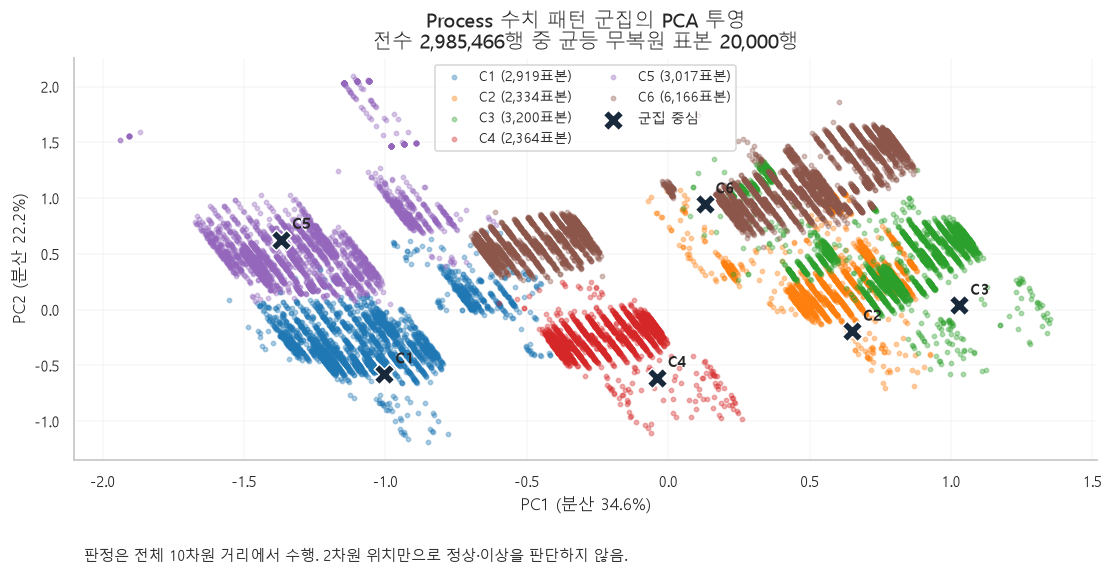

,전체 모델 평가 행,PCA 그림 표본 행
source_period,,
25년12월24일-26년4월6일,2877903,19307
26년8월15일-26년9월14일,81454,529
26년9월30일-26년10월2일,26109,164


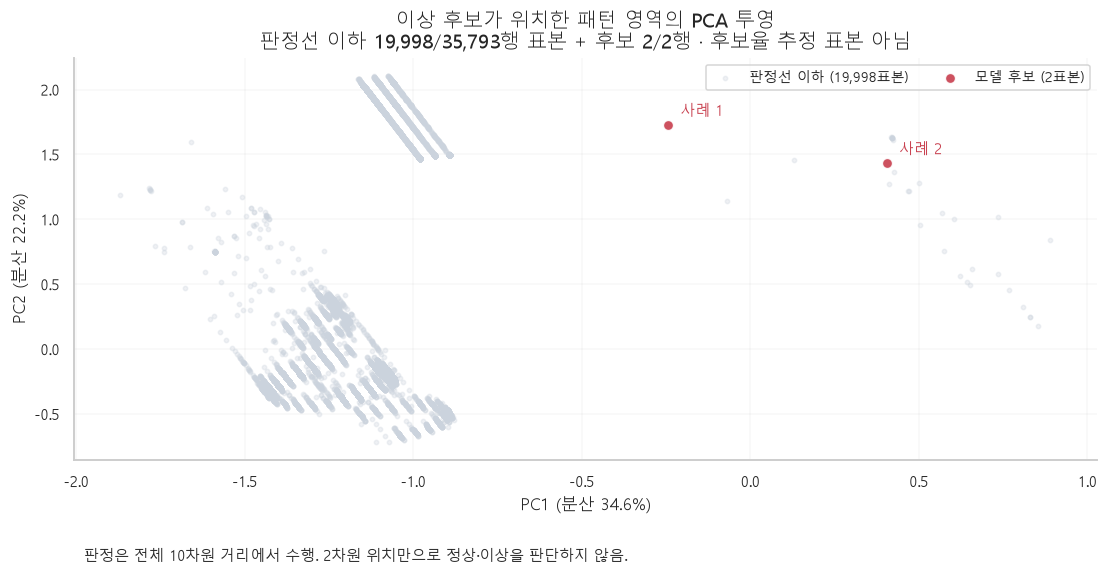

**실제 결과**: PCA 두 축의 학습 분산 설명 비중 합계는 56.80%. 전체 군집 그림은 20,000행 표본이다.

**의미**: 2차원에서 보이지 않는 차원도 실제 중심 거리와 이상 판정에 영향을 준다. PCA 중심에 2차원 원을 그려 실제 판정선인 것처럼 표시하지 않는다.

**모델 개발에 반영**: 산점도는 위치를 이해하는 보조 그림으로 사용하고 실제 판정은 거리·군집 판정선 표에서 확인한다.

In [11]:
plot_index = plot_projection(bundle, processes.loc[scoreable], scored, color_by="cluster")
sampling_by_period = pd.concat([
    processes.loc[scoreable].source_period.value_counts().rename("전체 모델 평가 행"),
    processes.loc[plot_index].source_period.value_counts().rename("PCA 그림 표본 행"),
], axis=1).fillna(0).astype(int)
display(sampling_by_period)
plot_projection(bundle, test_frame, test_result, color_by="candidate")
explain(
    f"PCA 두 축의 학습 분산 설명 비중 합계는 {bundle['pca'].explained_variance_ratio_.sum():.2%}. 전체 군집 그림은 {len(plot_index):,}행 표본이다.",
    "2차원에서 보이지 않는 차원도 실제 중심 거리와 이상 판정에 영향을 준다. PCA 중심에 2차원 원을 그려 실제 판정선인 것처럼 표시하지 않는다.",
    "산점도는 위치를 이해하는 보조 그림으로 사용하고 실제 판정은 거리·군집 판정선 표에서 확인한다.",
)


### Adapter별 군집 구성

전체 Adapter×군집 교차표는 전수 행 수를 보여준다. 아래 막대그래프는 평가 행이 많은 상위 8개 Adapter의 **Adapter 내부 군집 비중**이다. 어댑터마다 다른 패턴이 있는지, 같은 어댑터가 여러 패턴으로 나뉘는지 확인한다.


,C1,C2,C3,C4,C5,C6,합계
adapterType,,,,,,,
DB.READER,397492,291410,383846,327331,11911,5,1411995
DB.WRITER,383,24541,55524,13,409682,921596,1411739
SERVICE.EXECUTOR,25978,21663,21115,10028,30510,605,109899
FILE.READER,4069,4809,6686,8287,641,12,24504
FILE.WRITER,2795,4768,6639,8202,41,0,22445
DB.EXECUTOR,4434,0,10,0,32,0,4476
DB.UPDATER,36,6,25,0,10,0,77
DATA.TRANSFORMER,25,29,10,0,6,0,70
DATA.MAPPER,21,4,22,0,8,0,55


,C1,C2,C3,C4,C5,C6
adapterType,,,,,,
DB.READER,28.15,20.64,27.18,23.18,0.84,0.00
DB.WRITER,0.03,1.74,3.93,0.00,29.02,65.28
SERVICE.EXECUTOR,23.64,19.71,19.21,9.12,27.76,0.55
FILE.READER,16.61,19.63,27.29,33.82,2.62,0.05
FILE.WRITER,12.45,21.24,29.58,36.54,0.18,0.00
DB.EXECUTOR,99.06,0.00,0.22,0.00,0.71,0.00
DB.UPDATER,46.75,7.79,32.47,0.00,12.99,0.00
DATA.TRANSFORMER,35.71,41.43,14.29,0.00,8.57,0.00
DATA.MAPPER,38.18,7.27,40.00,0.00,14.55,0.00


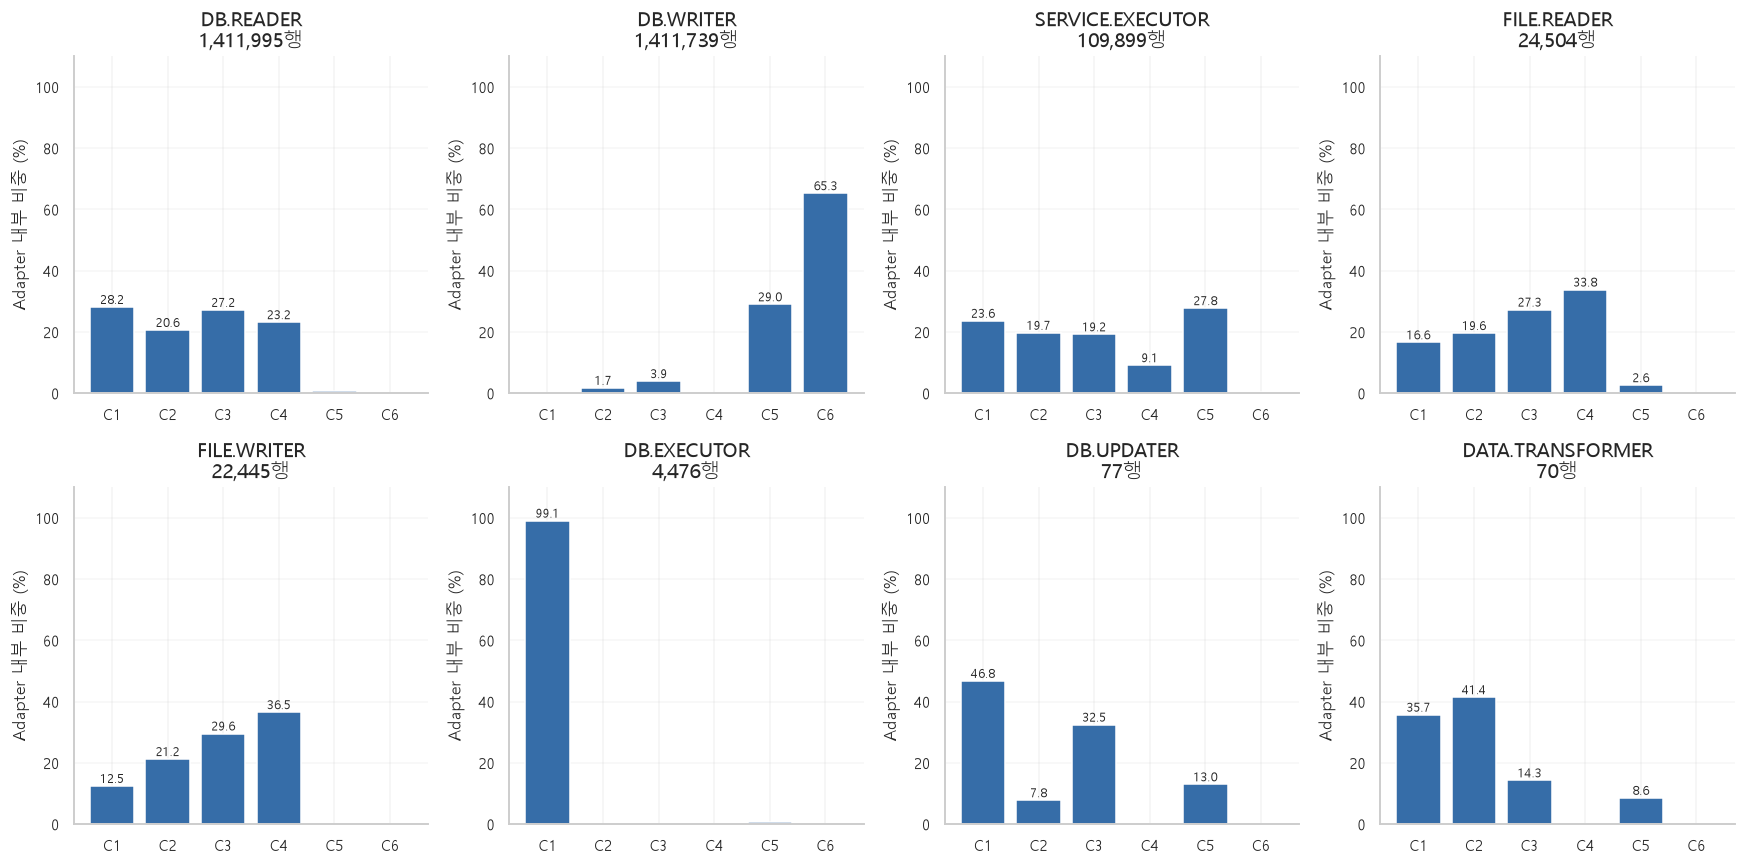

**실제 결과**: 평가된 23개 Adapter 중 22개가 두 군집 이상에 나타난다.

**의미**: Adapter는 역할 범주이고 군집은 수치·시간 패턴 범주라 일대일 매핑이 필수는 아니다.

**모델 개발에 반영**: Adapter 내부에 여러 정상 패턴이 있는 경우 군집 기반 기준이 도움이 되는지 검토하되 드문 군집 자체를 이상으로 처리하지 않는다.

In [12]:
adapter_cluster_counts = pd.crosstab(
    processes.loc[scored.index, "adapterType"].astype("string").fillna("결측"),
    scored.cluster,
).reindex(columns=range(KM_CONFIG.selected_k), fill_value=0)
adapter_cluster_counts.columns = [cluster_name(c) for c in adapter_cluster_counts.columns]
adapter_cluster_counts["합계"] = adapter_cluster_counts.sum(axis=1)
adapter_cluster_counts = adapter_cluster_counts.sort_values("합계", ascending=False)
display(adapter_cluster_counts)
adapter_cluster_pct = adapter_cluster_counts.drop(columns="합계").div(adapter_cluster_counts["합계"], axis=0) * 100
display(adapter_cluster_pct.round(2))
top_adapters = adapter_cluster_counts.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(16, 8), squeeze=False)
for ax, adapter in zip(axes.ravel(), top_adapters):
    values = adapter_cluster_pct.loc[adapter]
    ax.bar(values.index, values, color=BLUE)
    ax.set(title=f"{adapter}\n{int(adapter_cluster_counts.loc[adapter, '합계']):,}행", ylabel="Adapter 내부 비중 (%)", ylim=(0, 110))
    for i, value in enumerate(values):
        if value >= 1:
            ax.text(i, value + 1, f"{value:.1f}", ha="center", fontsize=8)
    ax.grid(axis="y", alpha=.18)
for ax in axes.ravel()[len(top_adapters):]:
    ax.set_visible(False)
finish(fig)
mixed = int((adapter_cluster_counts.drop(columns="합계").gt(0).sum(axis=1) > 1).sum())
explain(
    f"평가된 {len(adapter_cluster_counts):,}개 Adapter 중 {mixed:,}개가 두 군집 이상에 나타난다.",
    "Adapter는 역할 범주이고 군집은 수치·시간 패턴 범주라 일대일 매핑이 필수는 아니다.",
    "Adapter 내부에 여러 정상 패턴이 있는 경우 군집 기반 기준이 도움이 되는지 검토하되 드문 군집 자체를 이상으로 처리하지 않는다.",
)


## 7. 이후 test 분포와 판정선

아래 그림은 **test 실제 모델 평가 대상 전수**로 계산한 일반 막대그래프와 히스토그램이다. 먼저 처리시간·처리건수 분포를 확인한다. 다음 초과폭 그림에서는 군집별 판정선이 달라 공통 기준으로 비교할 수 있도록 **거리 − 군집 판정선**을 사용한다.

- 점선 0 오른쪽: 모델 후보.
- 점선 0 왼쪽 또는 동일: 판정선 이하.
- 아래 군집별 그림의 점선: **해당 군집의 실제 거리 판정선**.

확대 범위 밖 행은 그림 아래 표시하며 후보 집계에서는 제외하지 않는다.


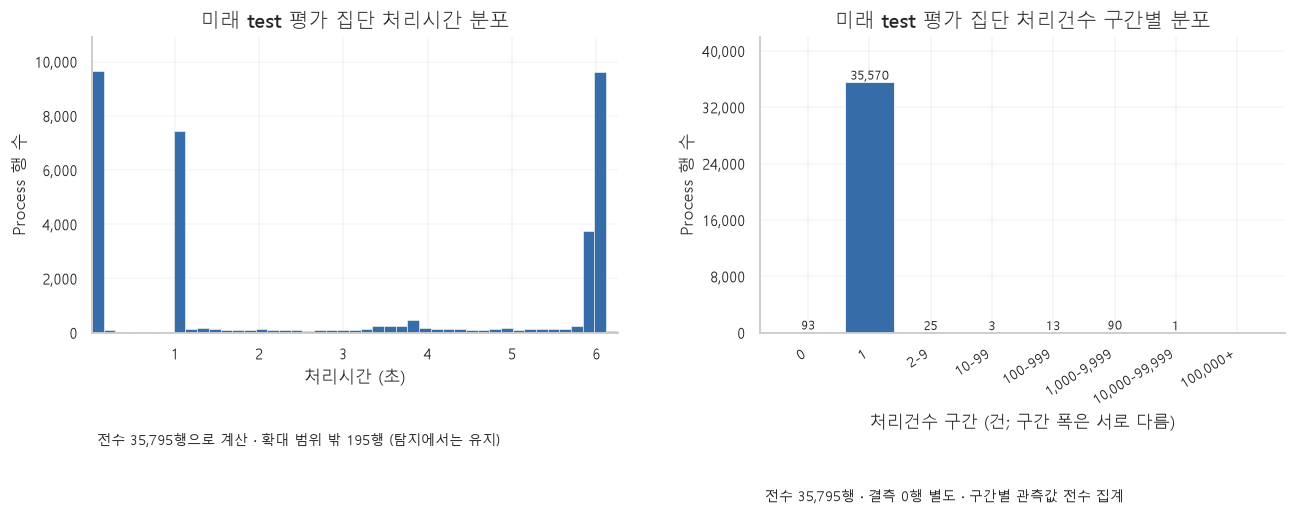

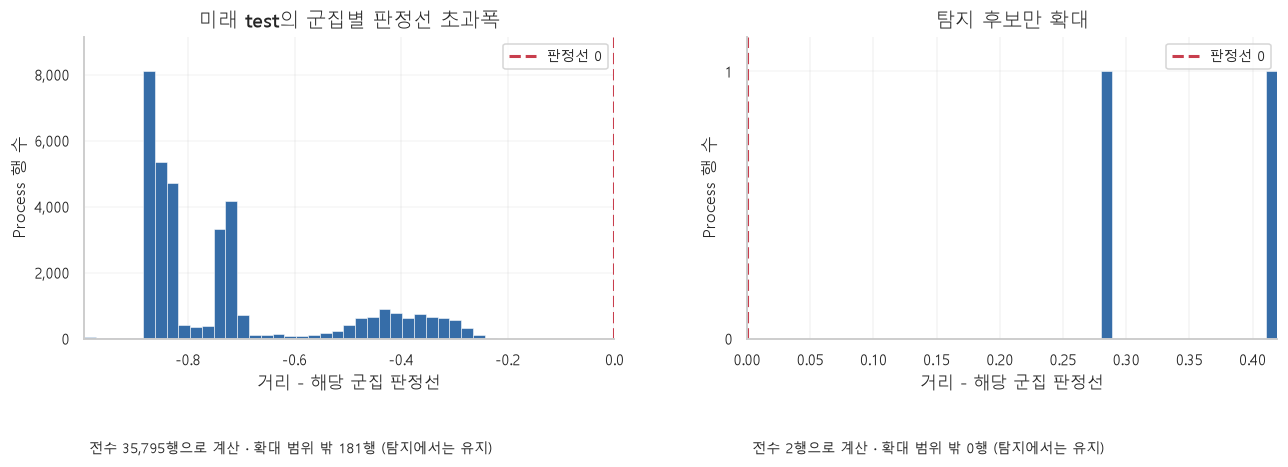

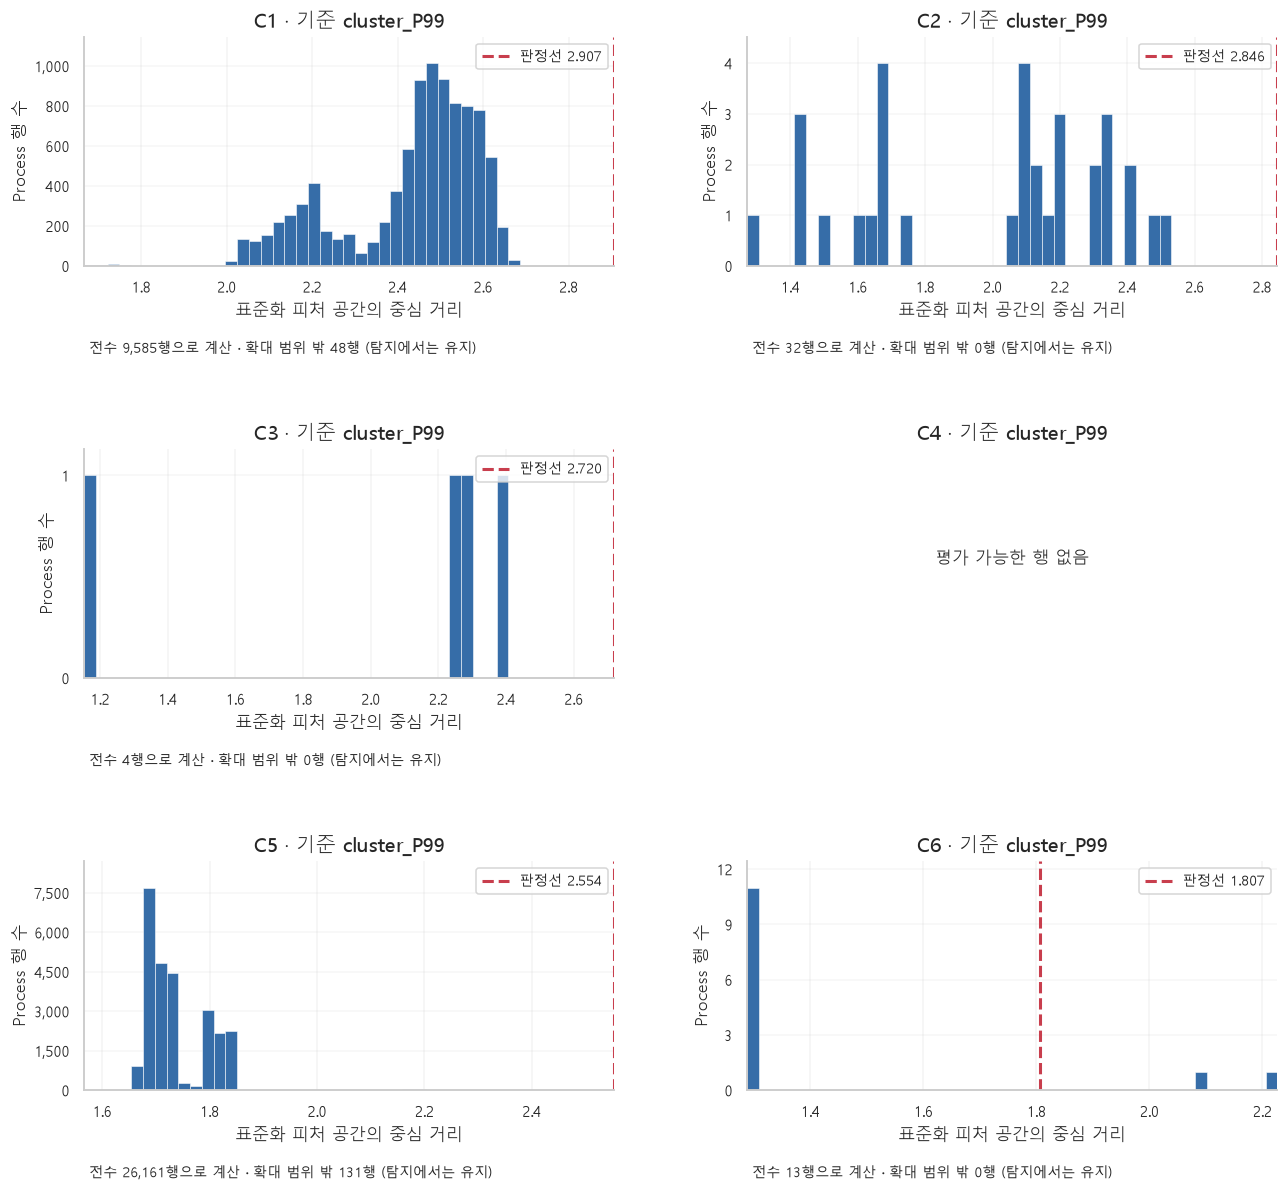

,군집,test 평가 행,test 후보,거리 판정선,기준 출처
0,C1,9585,0,2.907380,cluster_P99
1,C2,32,0,2.845971,cluster_P99
2,C3,4,0,2.720267,cluster_P99
3,C4,0,0,2.509082,cluster_P99
4,C5,26161,0,2.553978,cluster_P99
5,C6,13,2,1.807011,cluster_P99


**실제 결과**: test 35,795행 중 2행이 자신의 군집 판정선을 초과했다.

**의미**: 전체 분포의 단일 처리시간 기준이 아니라 군집별 표준화된 다변량 거리 기준이다. 중심에서 멀어도 군집이 원래 넓게 퍼졌다면 판정선 이하일 수 있다.

**모델 개발에 반영**: 후보의 피처 조합과 기간·Adapter 구성 변화까지 확인한 뒤 경보 정책을 결정한다.

In [13]:
plot_input_distributions(test_frame, cohort_label="미래 test 평가 집단")
plot_score_margins(test_result)
plot_cluster_distances(bundle, test_result)
display(pd.DataFrame([
    {"군집": cluster_name(c), "test 평가 행": int(test_result.cluster.eq(c).sum()),
     "test 후보": int(test_result.loc[test_result.cluster.eq(c), "model_candidate"].sum()),
     "거리 판정선": bundle["thresholds"].set_index("cluster").loc[c, "distance_threshold"],
     "기준 출처": bundle["thresholds"].set_index("cluster").loc[c, "threshold_basis"]}
    for c in range(KM_CONFIG.selected_k)
]))
explain(
    f"test {len(test_result):,}행 중 {int(test_result.model_candidate.sum()):,}행이 자신의 군집 판정선을 초과했다.",
    "전체 분포의 단일 처리시간 기준이 아니라 군집별 표준화된 다변량 거리 기준이다. 중심에서 멀어도 군집이 원래 넓게 퍼졌다면 판정선 이하일 수 있다.",
    "후보의 피처 조합과 기간·Adapter 구성 변화까지 확인한 뒤 경보 정책을 결정한다.",
)


### 어느 시점·Adapter에서 후보가 늘어나는가?

시간 그래프는 test에 실제 관측된 날짜만 표시한다. 수집 공백을 트래픽 0으로 채우지 않는다. 날짜별 분모도 표시하고, 소수 표본의 높은 비율을 대규모 장애로 해석하지 않는다.


,rows,candidates,candidate_pct
date,,,
2026-08-20,7207,0,0.000000
2026-08-21,1246,0,0.000000
2026-08-24,9,0,0.000000
2026-08-27,7,0,0.000000
2026-08-28,8,0,0.000000
2026-08-31,10,0,0.000000
2026-09-03,1086,0,0.000000
2026-09-04,68,0,0.000000
2026-09-07,24,0,0.000000


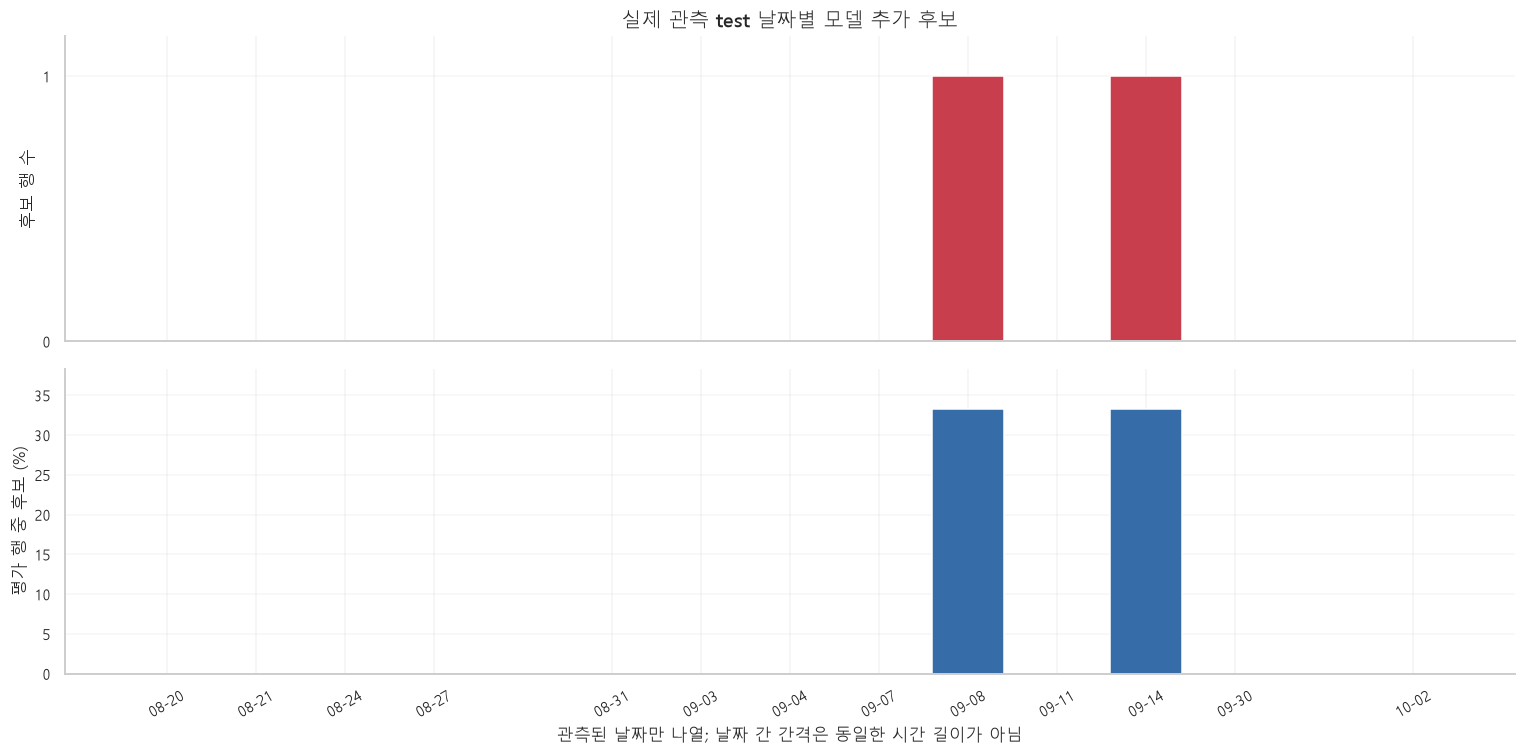

,rows,candidates,candidate_pct
adapter,,,
FILE.READER,30,1,3.333333
SERVICE.INVOKER,17,1,5.882353
CLIENT_STUB,3,0,0.000000
DB.DELETER,1,0,0.000000
DATA.MAPPER,14,0,0.000000
DB.EXECUTOR,1,0,0.000000
DB.READER,69,0,0.000000
DB.WRITER,81,0,0.000000
DATA.TRANSFORMER,10,0,0.000000


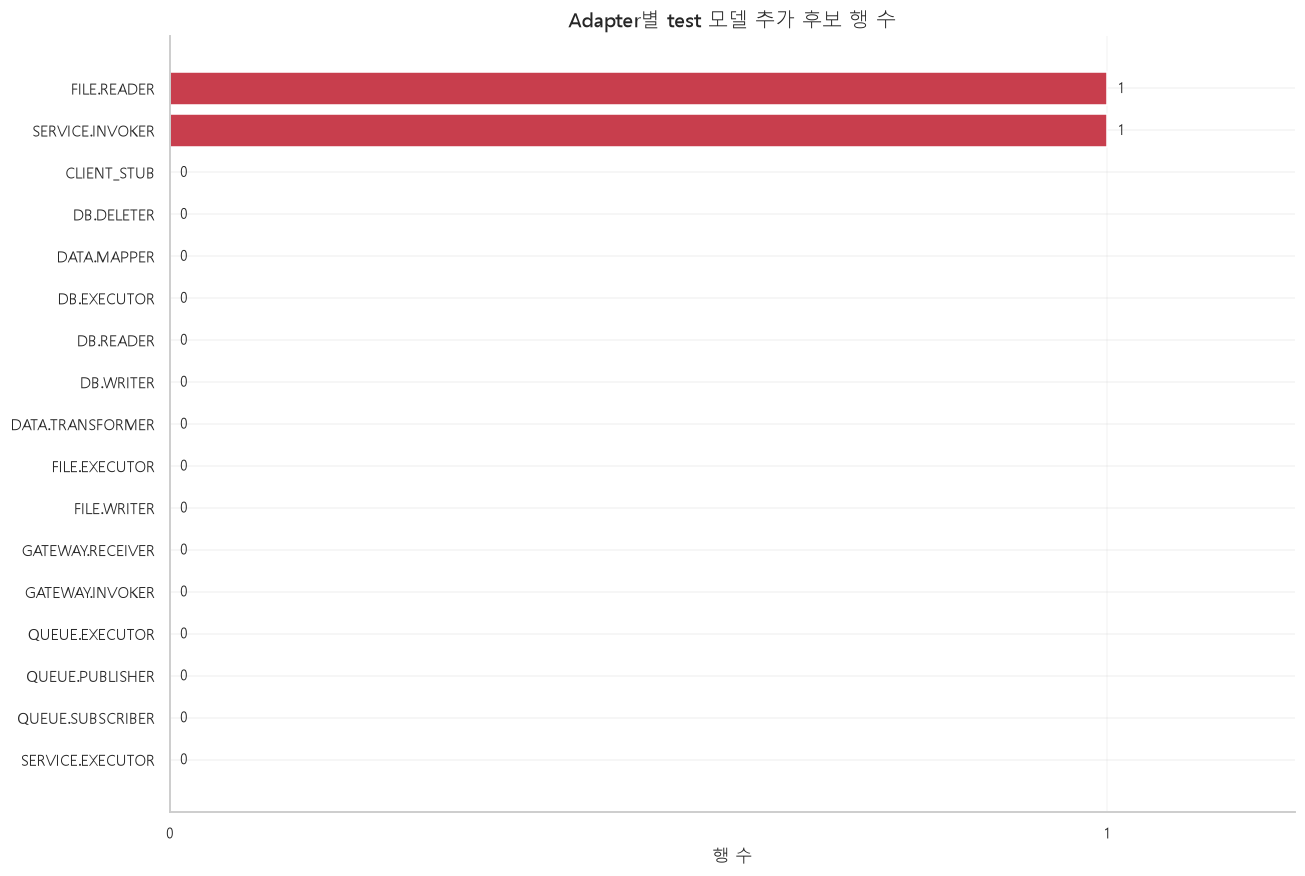

**실제 결과**: 최고 후보율 관측일 2026-09-08: 1/3행 (33.33%).

**의미**: 시점별 후보율 변화는 정상 패턴 이동·업무 구성 변화·이상 실행 중 어느 것인지 추가 확인해야 한다.

**모델 개발에 반영**: 날짜·Adapter별 분모를 함께 보며 후보율 상승을 장애 발생 사실로 단정하지 않는다.

In [14]:
daily = test_result[["model_candidate"]].assign(
    date=test_frame.startTime.dt.normalize(),
).groupby("date").agg(rows=("model_candidate", "size"), candidates=("model_candidate", "sum"))
daily["candidate_pct"] = daily.candidates / daily.rows * 100
display(daily)
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
x = np.arange(len(daily))
axes[0].bar(x, daily.candidates, color=RED)
axes[0].set(title="실제 관측 test 날짜별 모델 추가 후보", ylabel="후보 행 수", ylim=(0, max(int(daily.candidates.max()), 1) * 1.15))
count_axis(axes[0])
axes[1].bar(x, daily.candidate_pct, color=BLUE)
axes[1].set(ylabel="평가 행 중 후보 (%)", ylim=(0, max(float(daily.candidate_pct.max()), 1) * 1.15))
ticks = np.unique(np.r_[np.linspace(0, len(daily) - 1, min(len(daily), 12)).astype(int), np.flatnonzero(daily.candidates.to_numpy() > 0)])
axes[1].set_xticks(ticks, [daily.index[i].strftime("%m-%d") for i in ticks], rotation=30)
axes[1].set_xlabel("관측된 날짜만 나열; 날짜 간 간격은 동일한 시간 길이가 아님")
for ax in axes:
    ax.grid(axis="y", alpha=.18)
finish(fig)
test_adapter = test_result[["model_candidate"]].assign(adapter=test_frame.adapterType.astype("string").fillna("결측")).groupby("adapter").agg(
    rows=("model_candidate", "size"), candidates=("model_candidate", "sum"),
)
test_adapter["candidate_pct"] = test_adapter.candidates / test_adapter.rows * 100
test_adapter = test_adapter.sort_values("candidates", ascending=False)
display(test_adapter)
plot_counts(test_adapter.candidates, "Adapter별 test 모델 추가 후보 행 수", color=RED)
if len(daily):
    peak = daily.candidate_pct.idxmax()
    explain(
        f"최고 후보율 관측일 {peak:%Y-%m-%d}: {daily.loc[peak, 'candidates']:,.0f}/{daily.loc[peak, 'rows']:,.0f}행 ({daily.loc[peak, 'candidate_pct']:.2f}%).",
        "시점별 후보율 변화는 정상 패턴 이동·업무 구성 변화·이상 실행 중 어느 것인지 추가 확인해야 한다.",
        "날짜·Adapter별 분모를 함께 보며 후보율 상승을 장애 발생 사실로 단정하지 않는다.",
    )


## 8. 기존 GLOBAL IF와 같은 test 집단에서 비교

기존 저장 모델의 **GLOBAL IF 단독** 점수·GLOBAL 원시 P99 판정선을 읽어서 비교한다. 기존 운영 파이프라인의 **GLOBAL+Adapter 앙상블 결과와는 다르다.** K-means도 GLOBAL 단독이므로 우선 같은 구조에서 알고리즘 출력을 비교한다.

기본 설정에서 학습·분할·피처 정책이 일치하는지 확인한다. 기존 모델의 실제 학습 행 자체가 같은지 원본 전체 해시로 입증하는 비교는 아니므로, 새 데이터나 학습 정책이 달라졌다면 같은 실험에서 두 모델을 다시 학습해야 한다.

이미 하드 룰을 통과한 동일 test 행만 비교한다. 정답 라벨이 없으므로 후보 건수·중복은 표시하되 accuracy·precision·recall은 계산하지 않는다.


,동일 test Process 행 수
두 모델 모두 후보,0
K-means만 후보,2
GLOBAL IF만 후보,0
두 모델 모두 판정선 이하,35793


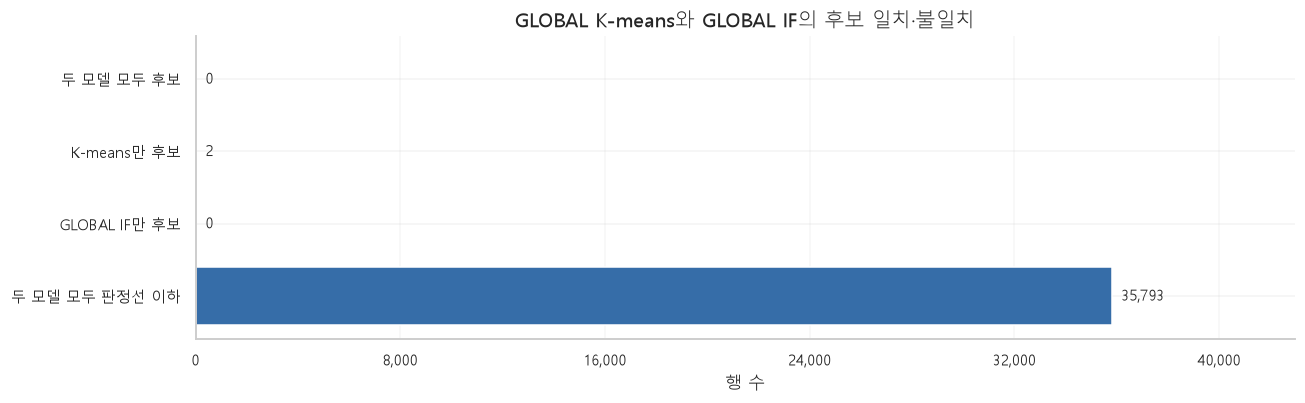

**실제 결과**: 동일 test 35,795행: K-means 2후보, GLOBAL IF 0후보, 교집합 0행.

**의미**: 불일치는 서로 다른 탐지 원리의 결과이며 한쪽이 맞다는 증거가 아니다. STATUS F는 이미 규칙에서 분리했으므로 F 탐지 수로 모델 성능을 평가하지 않는다.

**모델 개발에 반영**: 각 모델 전용 후보와 공통 후보에서 동일한 검토 예산으로 사례를 판독해 유효성을 비교한다.

In [15]:
IF_PATH = ROOT / "code" / "process_anomaly_pipeline" / "artifacts" / "process_if_v1.joblib"
if_result = None
if_comparison_note = "기존 IF 모델이 없어 비교 생략"
if IF_PATH.is_file() and TRAIN_STATUSES == ("S",):
    existing_if = ProcessAnomalyPipeline.load(IF_PATH, trusted=True)
    expected_splits = {
        name: int(split.eq(name).sum())
        for name in ["train", "calibration", "threshold", "test"]
    }
    saved_splits = {
        row["split"]: row["rows"] for row in existing_if.training_summary["splits"]
    }
    same_config = existing_if.config.to_dict() == RULE_CONFIG.to_dict()
    same_support = (
        existing_if.training_summary["rows"] == len(processes)
        and all(saved_splits.get(name) == count for name, count in expected_splits.items())
        and existing_if.global_model.support["train_rows"] == len(train)
        and existing_if.global_model.support["threshold_rows"] == len(threshold)
    )
    if same_config and same_support:
        if_result = comparison_if_global(existing_if, test_frame)
        km_flag = test_result.model_candidate
        if_flag = if_result.if_global_candidate
        cross = pd.Series({
            "두 모델 모두 후보": int((km_flag & if_flag).sum()),
            "K-means만 후보": int((km_flag & ~if_flag).sum()),
            "GLOBAL IF만 후보": int((~km_flag & if_flag).sum()),
            "두 모델 모두 판정선 이하": int((~km_flag & ~if_flag).sum()),
        })
        assert int(cross.sum()) == len(test_frame)
        display(cross.to_frame("동일 test Process 행 수"))
        plot_counts(cross, "GLOBAL K-means와 GLOBAL IF의 후보 일치·불일치")
        if_comparison_note = (
            f"동일 test {len(test_frame):,}행: K-means {int(km_flag.sum()):,}후보, "
            f"GLOBAL IF {int(if_flag.sum()):,}후보, 교집합 {int((km_flag & if_flag).sum()):,}행."
        )
    else:
        if_comparison_note = "기존 IF와 현재 실험의 설정·학습 지원 수가 달라 비교 생략"
elif TRAIN_STATUSES != ("S",):
    if_comparison_note = "학습 STATUS가 변경되어 기존 S-only IF와의 통제 비교 생략"
explain(
    if_comparison_note,
    "불일치는 서로 다른 탐지 원리의 결과이며 한쪽이 맞다는 증거가 아니다. STATUS F는 이미 규칙에서 분리했으므로 F 탐지 수로 모델 성능을 평가하지 않는다.",
    "각 모델 전용 후보와 공통 후보에서 동일한 검토 예산으로 사례를 판독해 유효성을 비교한다.",
)


## 9. 이상 후보 사례와 실제 탐지 근거

test에서 중심 거리 초과폭이 큰 후보 최대 6개를 확인한다. 상위 사례는 설명용이며 전체 탐지율의 표본 추정치가 아니다.

**탐지 근거**는 거리 > 군집 판정선이다. 아래 피처 막대는 **표준화 피처와 군집 중심 사이 제곱거리의 비중**으로, 정확히 거리²를 구성한다. 장애 원인, 인과 기여도, SHAP 값은 아니다.

시간대·요일이 막대에서 큰 비중을 차지한다면 처리량 병목보다 실행 시점의 패턴 차이가 점수를 주도한 사례일 수 있다.


,source_period,transactionId,processId,adapterType,status,startTime,부모 Transaction STATUS
3686765,26년8월15일-26년9월14일,TR-IF_SERVICEINVOKER_107-20260908154929301-01,IF_SERVICEINVOKER_107_PR001,SERVICE.INVOKER,S,2026-09-08 15:49:29.374,S
3604083,26년8월15일-26년9월14일,TR-IF_FILE2DB_000-20260914141958532-01,IF_FILE2DB_000_PR001,FILE.READER,S,2026-09-14 14:19:58.812,S


,totalCount,successCount,errorCount,retryCount,처리시간 (초),distance,distance_threshold,threshold_basis,score_margin,model_candidate,군집,GLOBAL IF 후보
3686765,1.0,1.0,0.0,0.0,1.436,2.22676,1.80701,cluster_P99,0.41974,True,C6,False
3604083,1.0,1.0,0.0,0.0,0.670,2.09021,1.80701,cluster_P99,0.28320,True,C6,False


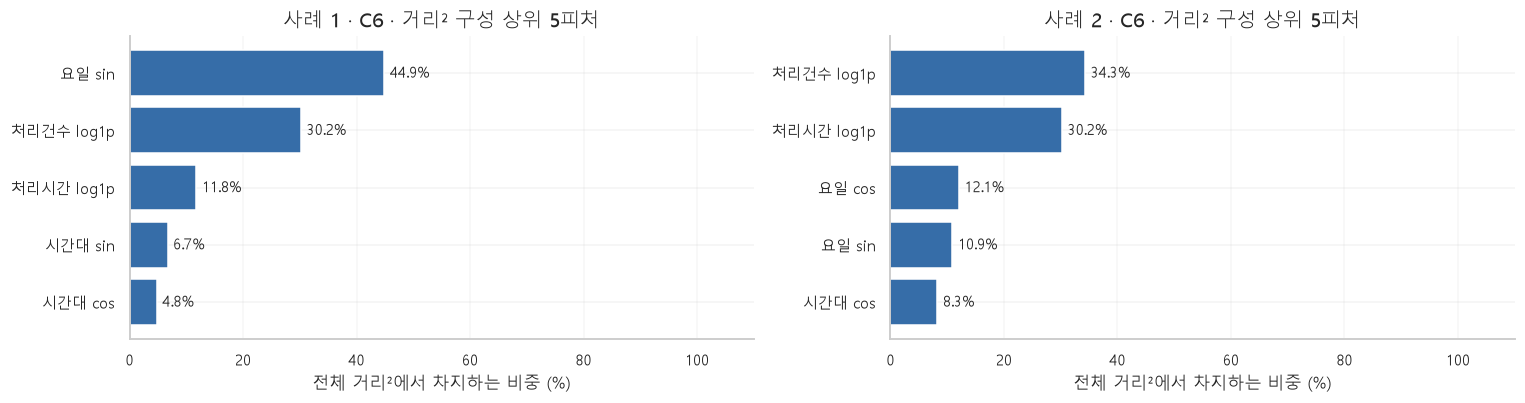

**실제 결과**: 사례 1: C6, 거리 2.22676 > 판정선 1.80701, 초과폭 0.41974; 거리² 최대 구성은 요일 sin (44.91%).

**의미**: 규칙 미탐지 test 행이 자신의 군집 기준선을 넘었다. 피처 비중은 중심과의 기하학적 차이를 설명한다.

**모델 개발에 반영**: 동일 업무의 처리량·시간대·운영 상황을 확인해 실제 이상인지 판단하고 검토 라벨을 축적한다.

**실제 결과**: 사례 2: C6, 거리 2.09021 > 판정선 1.80701, 초과폭 0.28320; 거리² 최대 구성은 처리건수 log1p (34.30%).

**의미**: 규칙 미탐지 test 행이 자신의 군집 기준선을 넘었다. 피처 비중은 중심과의 기하학적 차이를 설명한다.

**모델 개발에 반영**: 동일 업무의 처리량·시간대·운영 상황을 확인해 실제 이상인지 판단하고 검토 라벨을 축적한다.

In [16]:
candidate_cases = test_result.loc[test_result.model_candidate].nlargest(6, "score_margin")
if len(candidate_cases):
    case_ids = candidate_cases.index
    case_identity = processes.loc[case_ids, [
        "source_period", "transactionId", "processId", "adapterType", "status", "startTime",
    ]].copy()
    case_identity["부모 Transaction STATUS"] = transaction_context.loc[case_ids, "transactionStatus"]
    display(case_identity)
    case_values = processes.loc[case_ids, ["duration_ms", "totalCount", "successCount", "errorCount", "retryCount"]].copy()
    case_values["처리시간 (초)"] = case_values.pop("duration_ms") / 1000
    case_values = case_values.join(candidate_cases)
    case_values["군집"] = case_values.cluster.map(cluster_name)
    if if_result is not None:
        case_values["GLOBAL IF 후보"] = if_result.loc[case_ids, "if_global_candidate"]
    display(case_values.drop(columns="cluster").round(5))
    contributions = distance_contributions(bundle, processes.loc[case_ids])
    np.testing.assert_allclose(
        contributions.sum(axis=1).to_numpy(),
        candidate_cases.distance.to_numpy() ** 2,
        rtol=1e-5, atol=1e-5,
    )
    percentages = contributions.div(contributions.sum(axis=1), axis=0) * 100
    fig, axes = plt.subplots(int(np.ceil(len(case_ids) / 2)), 2, figsize=(14, 3.8 * np.ceil(len(case_ids) / 2)), squeeze=False)
    for ordinal, (row_id, ax) in enumerate(zip(case_ids, axes.ravel()), 1):
        values = percentages.loc[row_id].sort_values(ascending=False).head(5)
        ax.barh([FEATURE_LABELS.get(c, c) for c in values.index], values, color=BLUE)
        ax.invert_yaxis()
        ax.set(title=f"사례 {ordinal} · {case_values.loc[row_id, '군집']} · 거리² 구성 상위 5피처",
               xlabel="전체 거리²에서 차지하는 비중 (%)", xlim=(0, 110))
        for i, value in enumerate(values):
            ax.text(value + 1, i, f"{value:.1f}%", va="center", fontsize=10)
        ax.grid(axis="x", alpha=.18)
    for ax in axes.ravel()[len(case_ids):]:
        ax.set_visible(False)
    finish(fig)
    for ordinal, row_id in enumerate(case_ids, 1):
        row = candidate_cases.loc[row_id]
        top = percentages.loc[row_id].idxmax()
        explain(
            f"사례 {ordinal}: {cluster_name(row.cluster)}, 거리 {row.distance:.5f} > 판정선 {row.distance_threshold:.5f}, 초과폭 {row.score_margin:.5f}; 거리² 최대 구성은 {FEATURE_LABELS.get(top, top)} ({percentages.loc[row_id, top]:.2f}%).",
            "규칙 미탐지 test 행이 자신의 군집 기준선을 넘었다. 피처 비중은 중심과의 기하학적 차이를 설명한다.",
            "동일 업무의 처리량·시간대·운영 상황을 확인해 실제 이상인지 판단하고 검토 라벨을 축적한다.",
        )
else:
    display(Markdown("현재 설정에서 test 모델 추가 후보가 없어 사례 그래프를 생략한다. 후보를 만들기 위해 판정선을 임의로 낮추지 않는다."))


## 10. 결과 요약과 적용 한계

아래 요약은 실행 결과에서 생성한다. 기존 IF를 교체하거나 K-means를 앙상블에 추가하는 작업은 이 실험에 포함하지 않는다.

- 군집별 분포가 업무 특성을 대변하는지 확인해야 한다. 현재 ID·Adapter 자체는 거리 피처가 아니다.
- 새 ID도 익숙한 수치 패턴이면 기존 중심에 배정할 수 있지만, 새 업무의 정상 패턴이 학습 범위 밖이면 후보가 될 수 있다. 콜드스타트가 사라지는 것은 아니다.
- N/P의 장기 미처리·처리중은 완료 처리시간 모델과 별도로 수집 시각·경과시간·SLA가 필요하다.
- 이미 P99 꼬리를 규칙에서 제거했으므로 여기서 추가로 탐지한 것은 그 이후 남은 **다변량 거리 후보**이다.
- 백엔드 연결 시 전처리·중심·라벨 대응·군집별 판정선을 함께 고정한다. 요청 배치나 test마다 다시 fit하지 않는다.
- 재학습 안정성, K별 후보 유효성, STATUS 학습 정책 변화는 추가 실험이 필요하다.


In [17]:
fallback_clusters = int(bundle["thresholds"].threshold_basis.eq("GLOBAL_P99_fallback").sum())
test_candidates = int(test_result.model_candidate.sum())
summary = pd.DataFrame([
    ("원본 Process", f"{len(processes):,}행"),
    ("하드 룰 후보", f"{int(rule_hit.sum()):,}행"),
    ("규칙 미탐지 중 모델 미평가", f"{int((~rule_hit & ~scoreable).sum()):,}행"),
    ("전수 모델 평가", f"{len(scored):,}행"),
    ("실제 학습 표본", f"{len(bundle['train_sample']):,}행"),
    ("GLOBAL 군집 수", str(KM_CONFIG.selected_k)),
    ("군집 기준 지원 부족", f"{fallback_clusters}/{KM_CONFIG.selected_k}개 군집 (GLOBAL fallback)"),
    ("이후 test 평가", f"{len(test_result):,}행"),
    ("test 모델 추가 후보", f"{test_candidates:,}행 ({test_result.model_candidate.mean():.2%})"),
    ("IF 비교", if_comparison_note),
    ("정확도", "정답 라벨 없어 평가하지 않음"),
], columns=["항목", "실행 결과"])
display(summary)
reader_clusters = all_profiles.loc[all_profiles.top_adapter.eq("DB.READER")]
writer_clusters = all_profiles.loc[all_profiles.top_adapter.eq("DB.WRITER")]
observations = []
if len(reader_clusters):
    observations.append(
        f"DB.READER가 최다인 {len(reader_clusters)}개 군집의 처리시간 중앙값은 "
        f"{reader_clusters.median_duration_seconds.min():.3f}~{reader_clusters.median_duration_seconds.max():.3f}초이다."
    )
if len(writer_clusters):
    observations.append(
        f"DB.WRITER가 최다인 {len(writer_clusters)}개 군집의 처리시간 중앙값은 "
        f"{writer_clusters.median_duration_seconds.min():.3f}~{writer_clusters.median_duration_seconds.max():.3f}초이다."
    )
if len(diagnostics):
    observations.append(
        f"후보 K 중 silhouette 최고는 K={best_k}이며, 현재 K={KM_CONFIG.selected_k}이 최적이라는 근거는 없다."
    )
if len(test_profiles) and len(test_frame):
    dominant_test_cluster = test_profiles.loc[test_profiles.rows.idxmax()]
    observations.append(
        f"test 최다 군집 {cluster_name(dominant_test_cluster.cluster)}는 "
        f"{dominant_test_cluster.rows / len(test_frame):.2%}를 차지하고, "
        f"그 안에서 {dominant_test_cluster.top_adapter} 비중은 {dominant_test_cluster.top_adapter_pct:.2f}%다. "
        "전수·학습·test의 업무 구성을 구분해서 해석해야 한다."
    )
display(Markdown("**분포에서 확인한 특징**\n\n" + "\n".join("- " + text for text in observations)))
display(Markdown(
    f"**이번 실험 결론**: K={KM_CONFIG.selected_k}의 GLOBAL 수치 패턴 군집을 만들었고, "
    f"독립 검증 판정선을 고정해 이후 test {len(test_result):,}행 중 {test_candidates:,}행을 추가 검토 후보로 분리했다. "
    "Adapter 대응·군집 거리·사례의 거리 구성은 위 표와 그림에서 확인한다. "
    "후보 수가 많거나 silhouette이 높다는 이유만으로 기존 IF보다 우수하다고 결론내리지 않는다."
))


,항목,실행 결과
0,원본 Process,"3,714,199행"
1,하드 룰 후보,"167,310행"
2,규칙 미탐지 중 모델 미평가,"561,423행"
3,전수 모델 평가,"2,985,466행"
4,실제 학습 표본,"100,000행"
5,GLOBAL 군집 수,6
6,군집 기준 지원 부족,0/6개 군집 (GLOBAL fallback)
7,이후 test 평가,"35,795행"
8,test 모델 추가 후보,2행 (0.01%)
9,IF 비교,"동일 test 35,795행: K-means 2후보, GLOBAL IF 0후보, 교..."


**분포에서 확인한 특징**

- DB.READER가 최다인 4개 군집의 처리시간 중앙값은 0.337~0.450초이다.
- DB.WRITER가 최다인 2개 군집의 처리시간 중앙값은 3.996~6.603초이다.
- 후보 K 중 silhouette 최고는 K=2이며, 현재 K=6이 최적이라는 근거는 없다.
- test 최다 군집 C5는 73.09%를 차지하고, 그 안에서 SERVICE.EXECUTOR 비중은 99.59%다. 전수·학습·test의 업무 구성을 구분해서 해석해야 한다.

**이번 실험 결론**: K=6의 GLOBAL 수치 패턴 군집을 만들었고, 독립 검증 판정선을 고정해 이후 test 35,795행 중 2행을 추가 검토 후보로 분리했다. Adapter 대응·군집 거리·사례의 거리 구성은 위 표와 그림에서 확인한다. 후보 수가 많거나 silhouette이 높다는 이유만으로 기존 IF보다 우수하다고 결론내리지 않는다.